# 02 · Pick-rate difference-in-differences

Phase 5, steps 1–3 of `PLAN.md`: did each numeric tweak change how often players pick the card?
The design and the reasoning behind each choice are in `notes/phase5_deck_v3.pdf`. The estimation
code is in `src/spirometry/did.py`. This notebook calls it, prints the tables and has the plotting
code.

Sections, and the question each one answers:

0. **Setup and data checks**: which tables are we reading, and are duplicate uploads a problem?
1. **The tweaks**: what changed, by how much, and which ones we can estimate.
2. **Sample sizes**: how many offers each comparison has, before any estimate.
3. **Step 1, offer-rate check**: did any tweak change how often its card is *offered*?
4. **Step 2, one card by hand**: the 2×2 table, the regression, and how the options move it.
5. **Step 2b, week by week**: pre-trends and the path of the effect.
6. **All tweaks**: the main estimates.
7. **Robustness**: uploader groups, heavy uploaders, screen competition, bug-fix flags, and the
   second patch's thin before block.
8. **Step 3, dose-response**: effect against size of change.
9. **What to write down**.

The model, from `did.py`:

    picked ~ treat_post | card_id^upg + card_id^group + block^group + act + asc

It's a linear probability model (OLS on 0/1) with errors clustered by run. `treat_post` is 1 for
an offer of the changed card on the after build. β is the change in that card's pick probability
relative to unchanged cards of the same character. β = 0.03 means 3 percentage points.

**Version 2** (after PR #11): error bars are also compared against heteroskedasticity-robust
errors (`se_hc`); a fixed-horizon estimate (after-build weeks 0–3, section 6b) feeds the
dose-response; offer-rate flags are also measured against same-rarity controls; the
dose-response fit gets a patch term; section 0 checks what differs between copies of a
duplicated run.

**Version 3** (2026-09-29, after PR #12): rerun on the run tables from the first 1,393 pages
(parser 1.7.0), with the heavy-uploader check. Results in `SPIROMETRY.md` ("Phase 5
results"); the first pass's saved fits are in `data/analysis_p949/`.

**Run time.** Every fit uses a few hundred thousand to a few million offers. Sections 6 and 7 loop
over all 43 tweaks, several times over. Their results are saved to `data/analysis/` (git-ignored),
and a rerun loads them unless you set `FORCE = True`.

## 0. Setup

In [34]:
import os
import pathlib
import time

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Run from notebooks/ or the repo root. spirometry.did reads reference/ relative to the
# repo root, so move there.
ROOT = pathlib.Path.cwd()
if not (ROOT / "reference").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

from spirometry import did

REF = ROOT / "reference"
DB = ROOT / "data" / "runs" / "runs.duckdb"
OUT = ROOT / "data" / "analysis"          # git-ignored (data/)
OUT.mkdir(parents=True, exist_ok=True)
FORCE = False                              # True: refit instead of loading saved results

con = duckdb.connect(str(DB), read_only=True)
con.execute("SET enable_progress_bar = false")   # no Jupyter progress widgets in saved outputs

plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.5, "lines.markersize": 4,
})
pd.set_option("display.width", 160, "display.max_columns", 40, "display.max_rows", 120)

TREATED_C, CONTROL_C, GREY = "#e8702a", "#2a6fdb", "#555555"   # same colors as 01

### Which build of the run tables is this?

`primary_offers` keeps one record per `run_key` from parser 1.5.0 on. An older build can count a
solo run twice if it was uploaded by two routes. The check below says whether that matters on
your tables.

In [35]:
info = dict(con.execute("SELECT key, value FROM build_info").fetchall())
for k in ["parser_version", "built_at_utc", "records_read", "pages_failed",
          "solo_run_keys_multi_record", "primary_offers_dedup_removed",
          "solo_old_run_keys_split"]:
    print(f"{k:32s} {info.get(k, '(not in this build)')}")

PARSER = tuple(int(x) for x in info["parser_version"].split("."))
if PARSER < (1, 5, 0):
    print("\nBuilt before 1.5.0: primary_offers is NOT deduplicated by run_key. "
          "The next cell measures how much that matters.")
if PARSER < (1, 6, 0):
    print("Built before 1.6.0: run_key is seed|start_time only, so a few different runs "
          "share a key (18 on the 949-page tables). Harmless for these fits; the rebuild fixes it.")

parser_version                   1.7.0
built_at_utc                     2026-09-28T23:08:40+00:00
records_read                     1391858
pages_failed                     
solo_run_keys_multi_record       119
primary_offers_dedup_removed     4061
solo_old_run_keys_split          28


In [36]:
# Solo run_keys with more than one record (the SQL from PR #9, summarized).
# mixed_tag: copies disagree on the SlayTheStats tag (which uploader group the run lands in).
# likely_collision: copies disagree on character or ascension, so probably two different runs
# that happen to share seed and start time.
dups = con.execute('''
    WITH m AS (
        SELECT r.run_key,
               count(DISTINCT r.run_hash)                   AS n_records,
               count(DISTINCT r.uploader_tag IS NOT NULL)   AS n_tag_states,
               count(DISTINCT p.character)                  AS n_char,
               count(DISTINCT r.ascension)                  AS n_asc,
               count(DISTINCT r.record_digest)              AS n_digest
        FROM runs r JOIN run_players p USING (run_hash)
        WHERE r.n_players = 1
        GROUP BY r.run_key HAVING count(DISTINCT r.run_hash) > 1)
    SELECT count(*)                               AS run_keys,
           coalesce(sum(n_records), 0)            AS records,
           coalesce(sum(n_tag_states > 1), 0)     AS mixed_tag,
           coalesce(sum(n_char > 1 OR n_asc > 1), 0) AS likely_collision,
           coalesce(sum(n_digest > 1), 0)         AS content_differs
    FROM m''').df()
n_solo = con.execute("SELECT count(DISTINCT run_key) FROM runs WHERE n_players = 1").fetchone()[0]
display(dups)
print(f"solo run_keys in the tables: {n_solo:,}; with more than one record: "
      f"{dups.run_keys.item():,} ({dups.run_keys.item() / n_solo:.2%})")

,run_keys,records,mixed_tag,likely_collision,content_differs
0,119,240.0,4.0,0.0,119.0


solo run_keys in the tables: 798,425; with more than one record: 119 (0.01%)


In [37]:
# Do the copies of a duplicated solo run differ in the game itself, or only in upload
# stamps (_sts, _spirecodex_damage)? If win, floors or abandonment differ, "keep the first
# copy by page" may keep the less complete one, and the dedup rule needs changing.
# (On a pre-1.6.0 build this also counts the different runs that share a key; from 1.6.0
# on, only true duplicates are left.)
copies = con.execute('''
    SELECT count(*)                          AS dup_keys,
           coalesce(sum(n_win > 1), 0)       AS win_differs,
           coalesce(sum(n_floors > 1), 0)    AS floors_differ,
           coalesce(sum(n_aband > 1), 0)     AS abandoned_differs
    FROM (SELECT run_key,
                 count(DISTINCT win)            AS n_win,
                 count(DISTINCT floors_reached) AS n_floors,
                 count(DISTINCT was_abandoned)  AS n_aband
          FROM runs WHERE n_players = 1
          GROUP BY run_key HAVING count(*) > 1)''').df()
display(copies)

,dup_keys,win_differs,floors_differ,abandoned_differs
0,119,25.0,78.0,36.0


If the share is a fraction of a percent, the double counting doesn't move anything. If it's
several percent, and mostly `mixed_tag`, check the uploader-group results. (From parser 1.5.0
`primary_offers` keeps one copy per `run_key` anyway; from 1.7.0 the win tables drop runs
whose copies differ, `retried`.) In the second table, zeros mean the
copies are the same run with different upload stamps, so which copy is kept doesn't matter.

## 1. The tweaks

`reference/tweak_sizes.csv` has one row per numeric tweak. The **main field** is the number whose
change we use as the "dose". `log_ratio` = ln(new/old), so 6 → 8 and 8 → 6 are equal steps in
opposite directions. `direction` = +1 means a bigger number makes the card stronger. It's +1
everywhere, but please check that for each card. That's your review, not the code's.

In [38]:
TW = pd.read_csv(REF / "tweak_sizes.csv", dtype=str, keep_default_na=False).set_index("card_patch_id")
for c in ["log_ratio", "upgraded_log_ratio", "direction"]:
    TW[c] = pd.to_numeric(TW[c], errors="coerce")
TW["window"] = np.where(TW.before_builds == "v0.99.1", "first patch (v0.103.2)",
                        "second patch (v0.107.1)")
EST = TW[TW.solo_estimable == "yes"].sort_values(["window", "color", "card_id"])
print(f"{len(TW)} tweaks, {len(EST)} solo-estimable")
display(EST[["card_id", "color", "window", "main_field", "old", "new", "log_ratio",
             "upgrade_field", "upgrade_old", "upgrade_new", "upgrade_only",
             "mixed_direction", "direction", "note"]])

50 tweaks, 43 solo-estimable


,card_id,color,window,main_field,old,new,log_ratio,upgrade_field,upgrade_old,upgrade_new,upgrade_only,mixed_direction,direction,note
card_patch_id,,,,,,,,,,,,,,
FIGHT_ME@v0.103.2/patch,FIGHT_ME,ironclad,first patch (v0.103.2),powers_applied[0].amount,2,3,0.4055,,,,no,no,1,
HEMOKINESIS@v0.103.2/patch,HEMOKINESIS,ironclad,first patch (v0.103.2),damage,14,15,0.0690,,,,no,no,1,
DANSE_MACABRE@v0.103.2/patch,DANSE_MACABRE,necrobinder,first patch (v0.103.2),powers_applied[0].amount,3,4,0.2877,upgrade.dansemacabrepower,+1,+2,no,no,1,
DEBILITATE@v0.103.2/patch,DEBILITATE,necrobinder,first patch (v0.103.2),damage,7,10,0.3567,,,,no,no,1,
SCULPTING_STRIKE@v0.103.2/patch,SCULPTING_STRIKE,necrobinder,first patch (v0.103.2),damage,8,9,0.1178,,,,no,no,1,
COLLISION_COURSE@v0.103.2/patch,COLLISION_COURSE,regent,first patch (v0.103.2),damage,9,11,0.2007,upgrade.damage,+3,+4,no,no,1,
GATHER_LIGHT@v0.103.2/patch,GATHER_LIGHT,regent,first patch (v0.103.2),block,7,8,0.1335,,,,no,no,1,
GLITTERSTREAM@v0.103.2/patch,GLITTERSTREAM,regent,first patch (v0.103.2),vars.BlockNextTurn,4,5,0.2231,,,,no,no,1,
HEIRLOOM_HAMMER@v0.103.2/patch,HEIRLOOM_HAMMER,regent,first patch (v0.103.2),damage,17,20,0.1625,,,,no,no,1,


## 2. Sample sizes

This comes before any estimate. Each comparison is only as good as its smaller side. The treated
card's offers in each block matter most: controls have hundreds of thousands of offers, the
treated card has a few thousand.

A single SQL aggregate does this, so no big tables get loaded yet.

In [39]:
agg = con.execute('''
    SELECT character, build_id, card_id, upgraded, uploader_tag IS NOT NULL AS tagged,
           count(*) AS offers, sum(picked::INT) AS picks, count(DISTINCT run_key) AS runs
    FROM offers_with_version GROUP BY ALL''').df()
agg["color"] = agg.character.str.replace("CHARACTER.", "", regex=False).str.lower()

def block_of(build, t):
    if build in t.before_builds.split():
        return "before"
    if build in t.after_builds.split():
        return "after"
    return None

rows = []
for cpid, t in EST.iterrows():
    a = agg[(agg.color == t.color) & (agg.card_id == t.card_id)].copy()
    a["block"] = [block_of(b, t) for b in a.build_id]
    a = a[a.block.notna()]
    r = {"card_patch_id": cpid, "card": t.card_id, "window": t.window}
    for blk in ["before", "after"]:
        s = a[a.block == blk]
        r[f"offers_{blk}"] = int(s.offers.sum())
        r[f"upgraded_{blk}"] = int(s.offers[s.upgraded].sum())
        r[f"tagged_share_{blk}"] = s.offers[s.tagged].sum() / max(s.offers.sum(), 1)
        r[f"pick_rate_{blk}"] = s.picks.sum() / max(s.offers.sum(), 1)
    rows.append(r)
sizes = pd.DataFrame(rows).set_index("card_patch_id")
display(sizes.style.format({c: "{:.2f}" for c in sizes.columns if "share" in c or "rate" in c}))

,card,window,offers_before,upgraded_before,tagged_share_before,pick_rate_before,offers_after,upgraded_after,tagged_share_after,pick_rate_after
card_patch_id,,,,,,,,,,
FIGHT_ME@v0.103.2/patch,FIGHT_ME,first patch (v0.103.2),6853,1122,0.27,0.14,7943,1188,0.22,0.23
HEMOKINESIS@v0.103.2/patch,HEMOKINESIS,first patch (v0.103.2),6820,1098,0.27,0.16,8081,1256,0.22,0.19
DANSE_MACABRE@v0.103.2/patch,DANSE_MACABRE,first patch (v0.103.2),5870,993,0.26,0.07,6558,980,0.22,0.16
DEBILITATE@v0.103.2/patch,DEBILITATE,first patch (v0.103.2),5670,958,0.26,0.19,6223,862,0.22,0.25
SCULPTING_STRIKE@v0.103.2/patch,SCULPTING_STRIKE,first patch (v0.103.2),10246,1729,0.30,0.09,12416,1695,0.25,0.10
COLLISION_COURSE@v0.103.2/patch,COLLISION_COURSE,first patch (v0.103.2),15593,2409,0.25,0.07,18769,2814,0.24,0.13
GATHER_LIGHT@v0.103.2/patch,GATHER_LIGHT,first patch (v0.103.2),15706,2480,0.25,0.39,18484,2807,0.23,0.42
GLITTERSTREAM@v0.103.2/patch,GLITTERSTREAM,first patch (v0.103.2),15649,2545,0.26,0.14,18491,2933,0.23,0.17
HEIRLOOM_HAMMER@v0.103.2/patch,HEIRLOOM_HAMMER,first patch (v0.103.2),2697,79,0.25,0.14,3201,88,0.23,0.13


In [40]:
# Offers per stable build: how big is each block? (v0.103.3 is the second patch's before block.)
per_build = (agg[agg.build_id.isin(["v0.99.1", "v0.103.2", "v0.103.3", "v0.107.1"])]
             .groupby("build_id").agg(offers=("offers", "sum")))
per_build["runs"] = con.execute('''
    SELECT build_id, count(DISTINCT run_key) FROM offers_with_version
    WHERE build_id IN ('v0.99.1', 'v0.103.2', 'v0.103.3', 'v0.107.1') GROUP BY 1''').df().set_index("build_id").iloc[:, 0]
display(per_build)

,offers,runs
build_id,,
v0.103.2,3603866,93574
v0.103.3,2055422,55713
v0.107.1,6447212,173500
v0.99.1,3126976,79452


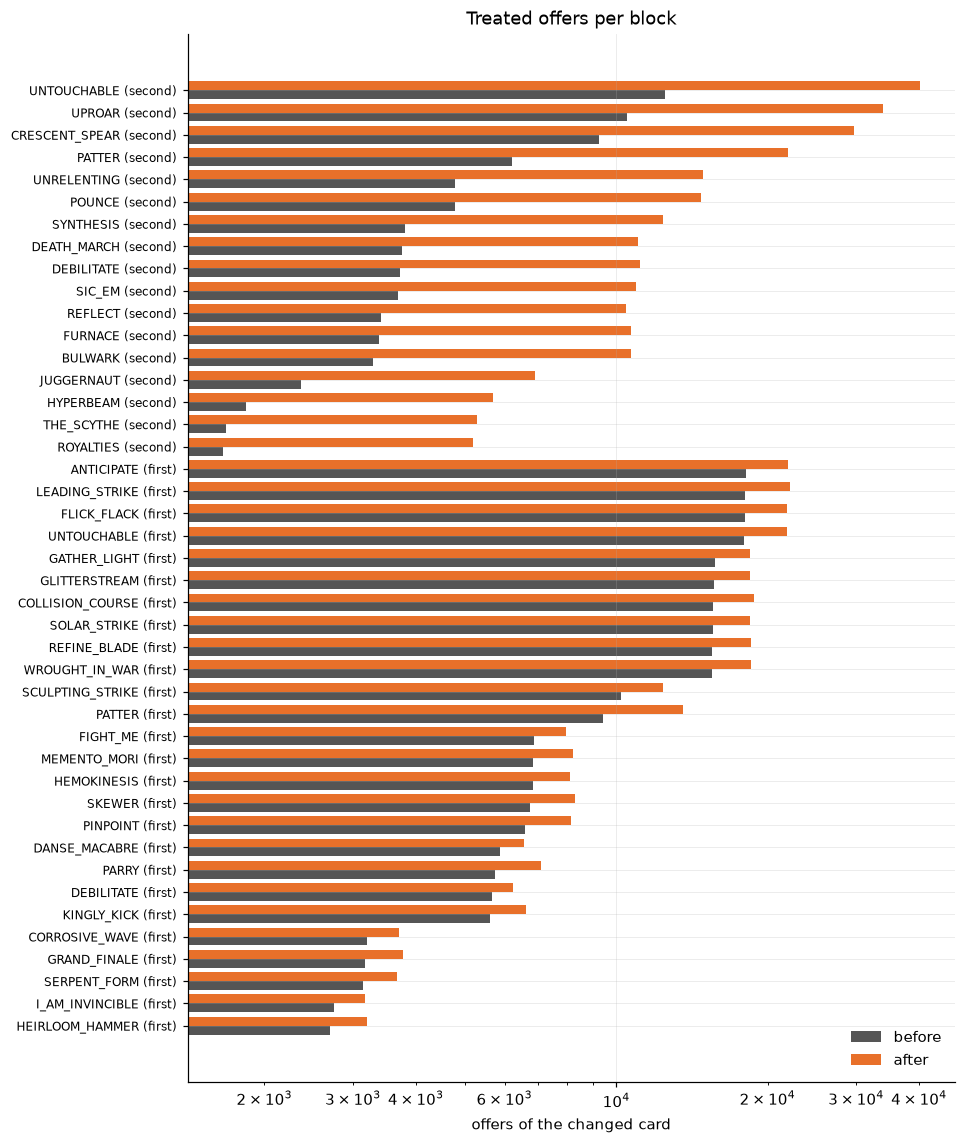

In [41]:
# Treated offers per side, per tweak (log scale). The smaller bar sets the error bar.
s = sizes.sort_values(["window", "offers_before"])
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(9, 0.26 * len(s) + 1.2))
ax.barh(y - 0.2, s.offers_before, height=0.4, color=GREY, label="before")
ax.barh(y + 0.2, s.offers_after, height=0.4, color=TREATED_C, label="after")
ax.set_yticks(y, [f"{c} ({w.split()[0]})" for c, w in zip(s.card, s.window)], fontsize=8)
ax.set(xscale="log", xlabel="offers of the changed card", title="Treated offers per block")
ax.legend(frameon=False, loc="lower right")
plt.show()


### 2b. Picking through a run

Context for every pick rate below. Late in a run, with a bigger deck, players skip reward
screens much more often, whatever the card. This shows how large that effect is, and checks
it doesn't bias the comparisons.

- **Pick rate per offered card** and **screen skip rate** (the player takes nothing) by
  floor, in the two big stable builds. The skip rate averages over offers, so a 3-card screen
  counts three times. Every screen has about 3 cards, so the shape is right.
- **Timing balance**: offers are random, so each tweak's card should have the same act mix
  before and after its patch. The table gives each card's share of act-3 offers in both
  blocks. Shifts shared by a character's cards are absorbed by the block term; only a
  card-specific shift could bias its estimate.


,first_floor,last_floor,skip_first,skip_last,pick_first,pick_last
act,,,,,,
1,2,17,0.052,0.058,0.316,0.312
2,19,35,0.254,0.124,0.246,0.289
3,35,48,0.383,0.395,0.203,0.199


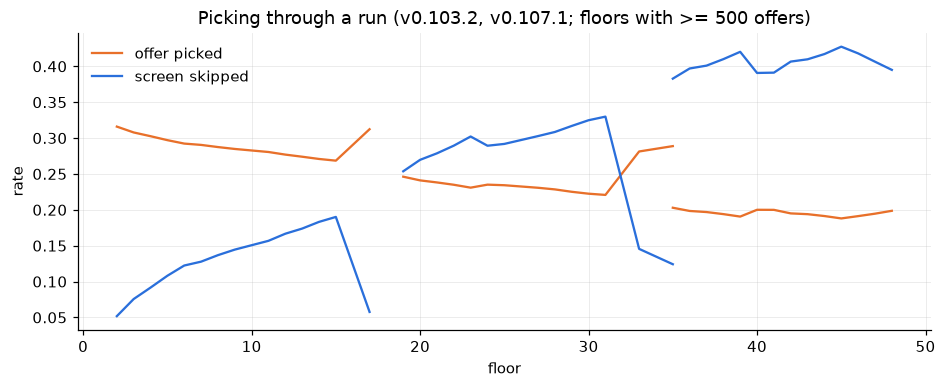

In [42]:

PT_BUILDS = ["v0.103.2", "v0.107.1"]
by_floor = con.execute('''
    SELECT act, floor, count(*) AS offers,
           avg(picked::INT)             AS pick_rate,
           1 - avg(set_picked_any::INT) AS skip_rate
    FROM offers_with_version
    WHERE list_contains(?, build_id)
    GROUP BY act, floor ORDER BY floor''', [PT_BUILDS]).df()
summ = by_floor[by_floor.offers >= 500].groupby("act").agg(
    first_floor=("floor", "min"), last_floor=("floor", "max"),
    skip_first=("skip_rate", "first"), skip_last=("skip_rate", "last"),
    pick_first=("pick_rate", "first"), pick_last=("pick_rate", "last"))
display(summ.style.format(precision=3))

fig, ax = plt.subplots(figsize=(10, 3.5))
for act, g in by_floor[by_floor.offers >= 500].groupby("act"):
    ax.plot(g.floor, g.pick_rate, color=TREATED_C, label="offer picked" if act == 1 else None)
    ax.plot(g.floor, g.skip_rate, color=CONTROL_C, label="screen skipped" if act == 1 else None)
ax.set(xlabel="floor", ylabel="rate",
       title=f"Picking through a run ({', '.join(PT_BUILDS)}; floors with >= 500 offers)")
ax.legend(frameon=False)
plt.show()


In [43]:

# Timing balance: each tweak's share of act-3 offers, before vs. after its patch.
rows = []
for cpid, t in EST.iterrows():
    before, after = t.before_builds.split(), t.after_builds.split()
    a = con.execute('''
        SELECT list_contains(?, build_id) AS after_block, act, count(*) AS n
        FROM offers_with_version
        WHERE card_id = ? AND list_contains(?, build_id)
        GROUP BY ALL''', [after, t.card_id, before + after]).df()
    tot = a.groupby("after_block").n.sum()
    act3 = a[a.act == 3].groupby("after_block").n.sum()
    rows.append({"card_patch_id": cpid, "card": t.card_id, "color": t.color,
                 "window": t.window,
                 "act3_share_before": act3.get(False, 0) / tot.get(False, np.nan),
                 "act3_share_after": act3.get(True, 0) / tot.get(True, np.nan)})
timing = pd.DataFrame(rows).set_index("card_patch_id")
timing["change"] = timing.act3_share_after - timing.act3_share_before
# The part of each card's shift not shared with its character in that patch:
timing["change_vs_character"] = timing.change - timing.groupby(["window", "color"]).change.transform("median")
display(timing.sort_values("change").style.format(precision=3))
print(f"change in act-3 share: median {timing.change.median():+.3f}, "
      f"range {timing.change.min():+.3f} .. {timing.change.max():+.3f}; "
      f"card-specific part: max |{timing.change_vs_character.abs().max():.3f}|")


,card,color,window,act3_share_before,act3_share_after,change,change_vs_character
card_patch_id,,,,,,,
CORROSIVE_WAVE@v0.103.2/patch,CORROSIVE_WAVE,silent,first patch (v0.103.2),0.086,0.055,-0.031,-0.016
SCULPTING_STRIKE@v0.103.2/patch,SCULPTING_STRIKE,necrobinder,first patch (v0.103.2),0.172,0.144,-0.029,-0.015
MEMENTO_MORI@v0.103.2/patch,MEMENTO_MORI,silent,first patch (v0.103.2),0.159,0.140,-0.019,-0.005
I_AM_INVINCIBLE@v0.103.2/patch,I_AM_INVINCIBLE,regent,first patch (v0.103.2),0.070,0.052,-0.018,-0.019
FLICK_FLACK@v0.103.2/patch,FLICK_FLACK,silent,first patch (v0.103.2),0.163,0.145,-0.018,-0.004
UNTOUCHABLE@v0.103.2/patch,UNTOUCHABLE,silent,first patch (v0.103.2),0.160,0.144,-0.016,-0.001
LEADING_STRIKE@v0.103.2/patch,LEADING_STRIKE,silent,first patch (v0.103.2),0.161,0.147,-0.014,-0.000
FURNACE@v0.107.1/patch,FURNACE,regent,second patch (v0.107.1),0.156,0.142,-0.014,-0.013
PINPOINT@v0.103.2/patch,PINPOINT,silent,first patch (v0.103.2),0.167,0.152,-0.014,0.000


change in act-3 share: median -0.001, range -0.031 .. +0.015; card-specific part: max |0.019|



How big could a timing shift's bias be? Take the pick-rate gap between act 1 and act 3
(about 10 points, from the plot) times the card-specific shift in its act-3 share. The largest
card-specific shift (about 2 points) gives about 0.2 points of pick rate, against the
1–15-point effects in section 6.


## 3. Step 1: offer-rate check

A number tweak should change how often a card is *picked*, not how often it's *offered*. For each
tweak, compare the card's share of its character's offers before and after, against the same
ratio for the unchanged cards. `did.offer_rate_check` measures the log share ratio against the
controls' median. Shares sum to one, so one card's jump moves all the others a little.

- `z_spread`: how unusual the ratio is next to the unchanged cards (median, and MAD scaled to an sd).
- `z_binom`: how far it is from their median in units of counting noise.
- `flag`: both beyond 3. A flagged card's pick-rate result needs a reason before it's used.
- `flag_rarity` and the `_rarity` z's: the same, measured against unchanged cards of the
  **same rarity** only. If a patch shrank one rarity's pool (a card changed rarity or was
  removed), every card of that rarity gets offered more. That flags them against all
  controls but not against their own rarity.
  - Flagged on `flag` but not `flag_rarity`: a pool change. The pick estimate is fine.
  - Flagged on both: something specific to that card changed how often it's offered.

  Rarity is the card's rarity *now*. Four card-patches changed rarity, so for those cards
  it may be wrong in one window.

Loading a window's offers is the slow part, so the helper keeps one window in memory at a time
and the loops go window by window.

In [44]:
_cache = {}

def window_data(color, before, after):
    key = (color, before, after)
    if key not in _cache:
        _cache.clear()                    # one window in memory at a time
        t0 = time.time()
        _cache[key] = did.load_block_data(con, color, before, after, ref=REF)
        print(f"  loaded {color} {before} -> {after}: {len(_cache[key]):,} offers "
              f"({time.time() - t0:.0f} s)")
    return _cache[key]

def data_for(cpid):
    t = TW.loc[cpid]
    return window_data(t.color, t.before_builds, t.after_builds)

def by_window(frame):
    '''Rows ordered so each window's data loads once.'''
    return frame.sort_values(["before_builds", "color", "card_id"])

In [45]:
orc_tables, rows = {}, []
for cpid, t in by_window(EST).iterrows():
    tab = did.offer_rate_check(data_for(cpid), cpid, ref=REF)
    orc_tables[cpid] = tab
    r = tab[tab.treated].iloc[0]
    rows.append({"card_patch_id": cpid, "card": t.card_id, "window": t.window,
                 **r[["rarity", "offers_before", "offers_after", "share_before",
                      "share_after", "log_share_ratio", "controls_median", "controls_mad",
                      "z_spread", "z_binom", "flag", "controls_median_rarity",
                      "n_controls_rarity", "z_spread_rarity", "z_binom_rarity",
                      "flag_rarity", "rarity_note"]].to_dict(),
                 "n_controls": int((~tab.treated).sum()),
                 "controls_flagged": int(tab.flag[~tab.treated].sum()),
                 "controls_flagged_rarity": int(tab.flag_rarity[~tab.treated].sum())})
orc = pd.DataFrame(rows).set_index("card_patch_id")
print(f"flagged against all controls: {int(orc.flag.sum())} of {len(orc)}; "
      f"against same-rarity controls: {int(orc.flag_rarity.sum())}")
display(orc.sort_values("z_binom", key=abs, ascending=False)
        .style.format(precision=3).apply(
            lambda r: ["background: #fde2cf" if (r.flag or r.flag_rarity) else ""
                       for _ in r], axis=1))

  loaded defect v0.103.3 -> v0.107.1: 1,622,401 offers (4 s)
  loaded ironclad v0.103.3 -> v0.107.1: 1,986,986 offers (3 s)
  loaded necrobinder v0.103.3 -> v0.107.1: 1,507,779 offers (3 s)
  loaded regent v0.103.3 -> v0.107.1: 1,403,829 offers (3 s)
  loaded silent v0.103.3 -> v0.107.1: 1,931,658 offers (3 s)
  loaded ironclad v0.99.1 -> v0.103.2: 1,497,659 offers (3 s)
  loaded necrobinder v0.99.1 -> v0.103.2: 1,203,553 offers (3 s)
  loaded regent v0.99.1 -> v0.103.2: 1,238,916 offers (2 s)
  loaded silent v0.99.1 -> v0.103.2: 1,448,566 offers (2 s)
flagged against all controls: 3 of 43; against same-rarity controls: 3


,card,window,rarity,offers_before,offers_after,share_before,share_after,log_share_ratio,controls_median,controls_mad,z_spread,z_binom,flag,controls_median_rarity,n_controls_rarity,z_spread_rarity,z_binom_rarity,flag_rarity,rarity_note,n_controls,controls_flagged,controls_flagged_rarity
card_patch_id,,,,,,,,,,,,,,,,,,,,,,
PATTER@v0.103.2/patch,PATTER,first patch (v0.103.2),Common,9429,13553,0.017,0.020,0.183,-0.010,0.019,10.258,14.531,True,-0.008,8,21.967,14.378,True,,56,2,2
SCULPTING_STRIKE@v0.103.2/patch,SCULPTING_STRIKE,first patch (v0.103.2),Common,10246,12416,0.018,0.020,0.115,-0.012,0.033,3.859,9.615,True,0.001,17,9.645,8.614,True,,72,2,4
PATTER@v0.107.1/patch,PATTER,second patch (v0.107.1),Common,6221,21923,0.019,0.020,0.092,-0.003,0.022,4.329,6.673,True,0.001,17,7.789,6.351,True,,67,0,0
DANSE_MACABRE@v0.103.2/patch,DANSE_MACABRE,first patch (v0.103.2),Uncommon,5870,6558,0.010,0.010,0.034,-0.012,0.033,1.392,2.566,False,-0.003,30,1.344,2.038,False,,72,2,4
JUGGERNAUT@v0.107.1/patch,JUGGERNAUT,second patch (v0.107.1),Rare,2365,6888,0.005,0.005,-0.060,-0.001,0.016,-3.702,-2.455,False,-0.019,22,-1.258,-1.698,False,,74,4,2
PARRY@v0.103.2/patch,PARRY,first patch (v0.103.2),Uncommon,5752,7098,0.010,0.011,0.030,-0.010,0.019,2.154,2.297,False,-0.010,30,1.598,2.281,False,,56,2,2
REFLECT@v0.107.1/patch,REFLECT,second patch (v0.107.1),Uncommon,3413,10472,0.010,0.010,-0.047,-0.003,0.022,-1.986,-2.221,False,-0.005,30,-2.249,-2.165,False,,67,0,0
CORROSIVE_WAVE@v0.103.2/patch,CORROSIVE_WAVE,first patch (v0.103.2),Rare,3203,3710,0.005,0.005,-0.032,0.017,0.028,-1.736,-2.045,False,-0.012,21,-0.763,-0.846,False,,66,2,1
HEMOKINESIS@v0.103.2/patch,HEMOKINESIS,first patch (v0.103.2),Uncommon,6820,8081,0.010,0.010,0.011,-0.022,0.021,1.567,2.012,False,-0.025,27,1.471,2.208,False,,68,4,4


`controls_flagged` (`controls_flagged_rarity`) is how many *unchanged* cards also cross both
thresholds against all (same-rarity) controls. A few per window
across ~80 cards is what noise and small pool changes give. Many means the character's pool
changed in that patch (cards added or removed, rarity changes), and the offer shares shifted for
everyone.

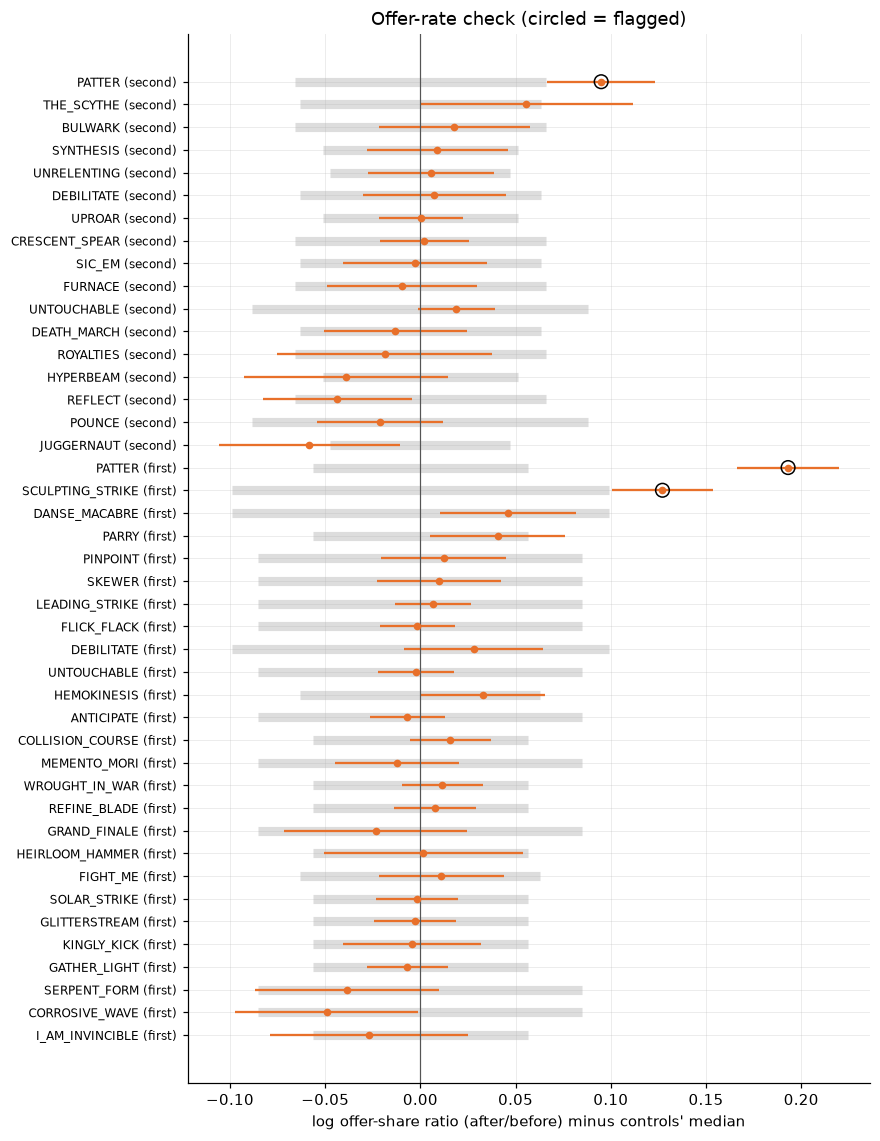

In [46]:
# Each tweak's offer-share change relative to its controls' median, with its counting noise
# (±2 binomial SE) and the controls' spread (±3 MAD, grey band).
o = orc.sort_values(["window", "log_share_ratio"])
d = o.log_share_ratio - o.controls_median
se = d / o.z_binom
y = np.arange(len(o))
fig, ax = plt.subplots(figsize=(8, 0.26 * len(o) + 1.2))
for i, (m, s3) in enumerate(zip(o.controls_mad, 3 * o.controls_mad)):
    ax.plot([-s3, s3], [i, i], color="#ddd", lw=6, solid_capstyle="butt", zorder=0)
ax.errorbar(d, y, xerr=2 * se, fmt="o", color=TREATED_C, ecolor=TREATED_C, capsize=0)
ax.scatter(d[o.flag], y[o.flag.to_numpy()], s=80, facecolors="none", edgecolors="k", zorder=3)
ax.axvline(0, color=GREY, lw=0.8)
ax.set_yticks(y, [f"{c} ({w.split()[0]})" for c, w in zip(o.card, o.window)], fontsize=8)
ax.set(xlabel="log offer-share ratio (after/before) minus controls' median",
       title="Offer-rate check (circled = flagged)")
plt.show()

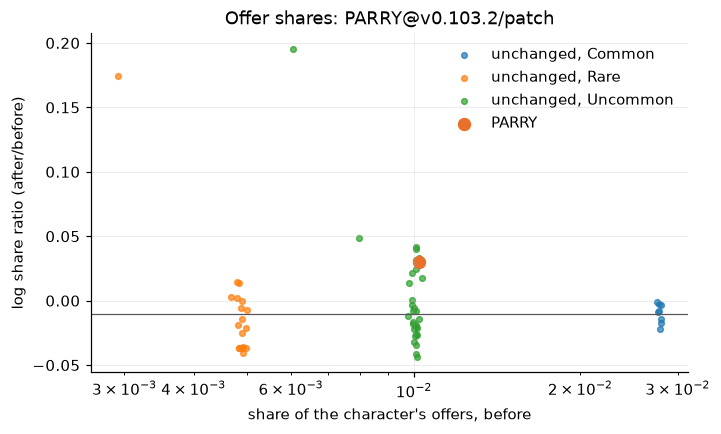

In [47]:
# One card in context: every card of that character, offer share before vs. its change.
# Rarity shows up as bands in share_before. The changed card should sit inside the cloud.
EXAMPLE = "PARRY@v0.103.2/patch" if "PARRY@v0.103.2/patch" in EST.index else EST.index[0]
tab = orc_tables[EXAMPLE]
fig, ax = plt.subplots(figsize=(7, 4))
c = tab[~tab.treated]
for rar, g in c.groupby("rarity"):
    ax.scatter(g.share_before, g.log_share_ratio, s=14, alpha=0.7,
               label=f"unchanged, {rar or 'no rarity'}")
t = tab[tab.treated]
ax.scatter(t.share_before, t.log_share_ratio, s=60, color=TREATED_C, label=TW.loc[EXAMPLE, "card_id"])
ax.axhline(tab.controls_median.iloc[0], color=GREY, lw=0.8)
ax.set(xscale="log", xlabel="share of the character's offers, before",
       ylabel="log share ratio (after/before)", title=f"Offer shares: {EXAMPLE}")
ax.legend(frameon=False)
plt.show()

## 4. Step 2: one card by hand

Before running 43 regressions, work through one and check that the regression does what the
2×2 table says.

**The raw difference-in-differences** uses the pick rate of the changed card and of the pooled
controls, before and after:

    DiD = (treated after − treated before) − (controls after − controls before)

The regression gives nearly the same number. It differs where the mix of offers shifted between
blocks: more upgraded offers, a different ascension mix, a different share of tagged uploaders.
The fixed effects compare like with like, so a big gap between the two numbers is worth
understanding.

In [48]:
print("example:", EXAMPLE)
df = data_for(EXAMPLE)
treated = TW.loc[EXAMPLE, "card_id"]
controls = did.control_cards(EXAMPLE, df=df, ref=REF)
sub = df[df.card_id.isin([treated] + controls)]
two_by_two = (sub.assign(who=np.where(sub.card_id == treated, "treated", "controls"))
              .pivot_table(index="who", columns="block", values="picked", aggfunc="mean",
                           observed=True)[["before", "after"]])
two_by_two["change"] = two_by_two.after - two_by_two.before
display(two_by_two.style.format("{:.4f}"))
raw_did = two_by_two.loc["treated", "change"] - two_by_two.loc["controls", "change"]
print(f"raw DiD: {raw_did:+.4f}   ({len(controls)} control cards)")

upg_only = TW.loc[EXAMPLE, "upgrade_only"] == "yes"
res = did.fit_did(df, EXAMPLE, upgraded=True if upg_only else None, ref=REF)
print(f"regression beta: {res['beta']:+.4f}  (se {res['se']:.4f}, 95% CI "
      f"{res['ci95'][0]:+.4f} .. {res['ci95'][1]:+.4f})")
print(f"clustered se / robust se: {res['se'] / res['se_hc']:.2f}   "
      f"(clustered / iid: {res['se'] / res['se_iid']:.2f})")
print(f"offers in fit: {res['n_offers']:,}  runs: {res['n_runs']:,}  treated offers: "
      f"{res['n_treated_offers']:,}  singletons dropped: {res['n_singletons_dropped']:,}")
print(res["formula"])

example: PARRY@v0.103.2/patch
  loaded regent v0.99.1 -> v0.103.2: 1,238,916 offers (2 s)


block,before,after,change
who,,,
controls,0.2751,0.2739,-0.0012
treated,0.1278,0.2777,0.1499


raw DiD: +0.1511   (56 control cards)
regression beta: +0.1505  (se 0.0075, 95% CI +0.1358 .. +0.1653)
clustered se / robust se: 1.08   (clustered / iid: 0.98)
offers in fit: 758,224  runs: 32,391  treated offers: 12,850  singletons dropped: 0
picked ~ treat_post | card_id^upg + card_id^group + block^group + act + asc


**Reading the error-bar ratios.** The same fit gives three error bars:

- `se_iid`: every offer independent and equally noisy.
- `se_hc` (robust): each offer can have its own noise, but they're independent.
- `se` (clustered by run, the main one): offers within a run can also be related.

So **clustered ÷ robust** isolates the within-run correlation. Above 1 means a run's offers of
this card aren't independent evidence, as with a run that keeps taking or skipping the same
card. **Clustered ÷ iid** mixes that with unequal noise between cards: a card picked 5% of the
time is less noisy than the average offer, which pulls the ratio below 1. That's why
Skewer's ratio is about 0.6.

In [ ]:
# The same card under each option (the checks from the deck's threat table).
TOP_N_UPLOADERS = 5
top_uploaders = (df[df.uploader_hash.notna()].groupby("uploader_hash", observed=True)
                 .run_key.nunique().nlargest(TOP_N_UPLOADERS))
print("top uploaders in this window (runs):", top_uploaders.to_dict())

VARIANTS = {
    "main": {},
    "pooled groups (no group terms)": dict(pooled_groups=True),
    "tagged only": dict(group="tagged"),
    "untagged only": dict(group="untagged"),
    "drop shared screens": dict(drop_shared_screens=True),
    "drop behavior-flagged controls": dict(drop_behavior_flags=True),
    f"drop top {TOP_N_UPLOADERS} uploaders": dict(drop_uploaders=list(top_uploaders.index)),
}
rows = []
for name, kw in VARIANTS.items():
    kw = dict(kw, upgraded=True) if upg_only else kw
    try:
        r = did.fit_did(df, EXAMPLE, ref=REF, **kw)
        rows.append({"variant": name, "beta": r["beta"], "se": r["se"],
                     "se/se_hc": r["se"] / r["se_hc"], "se/se_iid": r["se"] / r["se_iid"],
                     "n_offers": r["n_offers"],
                     "n_treated": r["n_treated_offers"]})
    except ValueError as e:
        rows.append({"variant": name, "error": str(e)})
display(pd.DataFrame(rows).set_index("variant").style.format(precision=4))

What to look for:

- **Pooled vs. main**: how much the uploader-group adjustment matters for this card. On the
  synthetic data a shifting uploader mix alone produced a fake +0.115.
- **Tagged vs. untagged**: same sign and roughly the same size? The groups rank cards
  differently, but a buff should help in both.
- **Drop shared screens**: should barely move. Only a few percent of control offers share a
  screen with any one card.
- **Top uploaders**: only covers uploads with a `player_token`, which is a minority of records.
  A big move means a few people drive the estimate.

## 5. Step 2b: week by week

The gap between the changed card and its controls, per week relative to the new build's release
(week 0 = the release week). The reference is the before build in week −1, so every point is
"how different from the week just before the release".

- **Before build, negative weeks**: should be flat around 0. A slope means the card was already
  drifting, and the DiD would credit that drift to the patch.
- **After build**: the path of the effect. There's usually a jump, then a drift while players
  learn.
- **Before build, weeks ≥ 0**: people still playing the old build after the release. If these
  move like the after build, it's calendar time (the meta), not the card change.

Weeks outside −6…8 are binned into the end weeks.

,week,block,coef,se,n_offers
0,-5,before,-0.019147,0.019483,381
1,-4,before,0.005177,0.014374,1661
2,-3,before,0.005005,0.014910,1432
3,-2,before,0.016678,0.015881,1118
4,0,after,0.144367,0.016468,1742
5,0,before,0.049329,0.036084,134
6,1,after,0.170950,0.018198,1216
7,1,before,0.107516,0.150238,8
8,2,after,0.134073,0.018554,1019
9,3,after,0.164242,0.021161,784


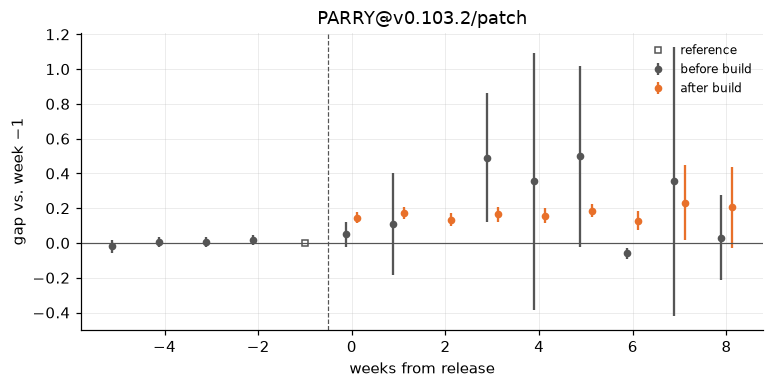

In [50]:
def plot_event_study(es, title, ax=None):
    ax = ax or plt.subplots(figsize=(8, 3.5))[1]
    for blk, color, dx in [("before", GREY, -0.12), ("after", TREATED_C, 0.12)]:
        e = es[es.block == blk]
        ax.errorbar(e.week + dx, e.coef, yerr=1.96 * e.se, fmt="o", color=color,
                    ecolor=color, capsize=0, label=f"{blk} build")
    ax.plot([-1], [0], marker="s", color=GREY, mfc="white", ls="none", label="reference")
    ax.axhline(0, color=GREY, lw=0.8)
    ax.axvline(-0.5, color=GREY, lw=0.8, ls="--")
    ax.set(title=title, xlabel="weeks from release", ylabel="gap vs. week −1")
    return ax

es_example = did.fit_event_study(df, EXAMPLE, upgraded=True if upg_only else None, ref=REF)
display(es_example.drop(columns="formula"))
ax = plot_event_study(es_example, EXAMPLE)
ax.legend(frameon=False, fontsize=8)
plt.show()

In [51]:
def pretrend_summary(es):
    '''Before-build cells with week < 0 (the reference week is absent). chi2 = sum of
    (coef/se)^2: an approximate joint test that they are all zero. It ignores the
    correlation between cells (they share the reference week), so read it as a screen, not
    a p-value to report. slope: weighted fit of coef on week, per week.'''
    pre = es[(es.block == "before") & (es.week < 0)].dropna(subset=["coef", "se"])
    if len(pre) < 2:
        return dict(n_pre=len(pre), chi2=np.nan, p=np.nan, slope=np.nan, slope_se=np.nan)
    z2 = ((pre.coef / pre.se) ** 2).sum()
    w = 1 / pre.se ** 2
    xm = np.average(pre.week, weights=w)
    sxx = (w * (pre.week - xm) ** 2).sum()
    slope = (w * (pre.week - xm) * pre.coef).sum() / sxx
    return dict(n_pre=len(pre), chi2=z2, p=stats.chi2.sf(z2, len(pre)), slope=slope,
                slope_se=1 / np.sqrt(sxx))

def all_event_studies():
    out = []
    for cpid, t in by_window(EST).iterrows():
        try:
            es = did.fit_event_study(data_for(cpid), cpid,
                                     upgraded=True if t.upgrade_only == "yes" else None, ref=REF)
            out.append(es.drop(columns="formula").assign(card_patch_id=cpid, error=""))
        except Exception as e:                  # report and keep going
            out.append(pd.DataFrame({"card_patch_id": [cpid],
                                     "error": [f"{type(e).__name__}: {e}"]}))
    return pd.concat(out, ignore_index=True)

path = OUT / "event_studies.parquet"
if path.exists() and not FORCE:
    ES = pd.read_parquet(path)
else:
    t0 = time.time()
    ES = all_event_studies()
    ES.to_parquet(path)
    print(f"event studies: {time.time() - t0:.0f} s")

pre = pd.DataFrame({cpid: pretrend_summary(g) for cpid, g in ES[ES.error == ""].groupby("card_patch_id")}).T
pre["card"] = TW.card_id.reindex(pre.index)
print("event-study errors:", ES.loc[ES.error != "", ["card_patch_id", "error"]].drop_duplicates().to_dict("records"))
display(pre.sort_values("p").style.format(precision=4))

event-study errors: []


,n_pre,chi2,p,slope,slope_se,card
COLLISION_COURSE@v0.103.2/patch,4.0000,35.3512,0.0000,-0.0034,0.0038,COLLISION_COURSE
UPROAR@v0.107.1/patch,2.0000,20.4078,0.0000,0.0005,0.0118,UPROAR
CORROSIVE_WAVE@v0.103.2/patch,4.0000,25.2395,0.0000,0.0064,0.0150,CORROSIVE_WAVE
FIGHT_ME@v0.103.2/patch,4.0000,16.7360,0.0022,-0.0176,0.0075,FIGHT_ME
ANTICIPATE@v0.103.2/patch,4.0000,16.4305,0.0025,0.0102,0.0047,ANTICIPATE
HEIRLOOM_HAMMER@v0.103.2/patch,4.0000,15.0642,0.0046,-0.0155,0.0114,HEIRLOOM_HAMMER
HYPERBEAM@v0.107.1/patch,2.0000,10.3094,0.0058,-0.0138,0.0263,HYPERBEAM
UNTOUCHABLE@v0.107.1/patch,2.0000,10.0711,0.0065,-0.0685,0.0383,UNTOUCHABLE
BULWARK@v0.107.1/patch,2.0000,8.7036,0.0129,0.0008,0.0331,BULWARK
WROUGHT_IN_WAR@v0.103.2/patch,4.0000,11.8646,0.0184,-0.0039,0.0049,WROUGHT_IN_WAR


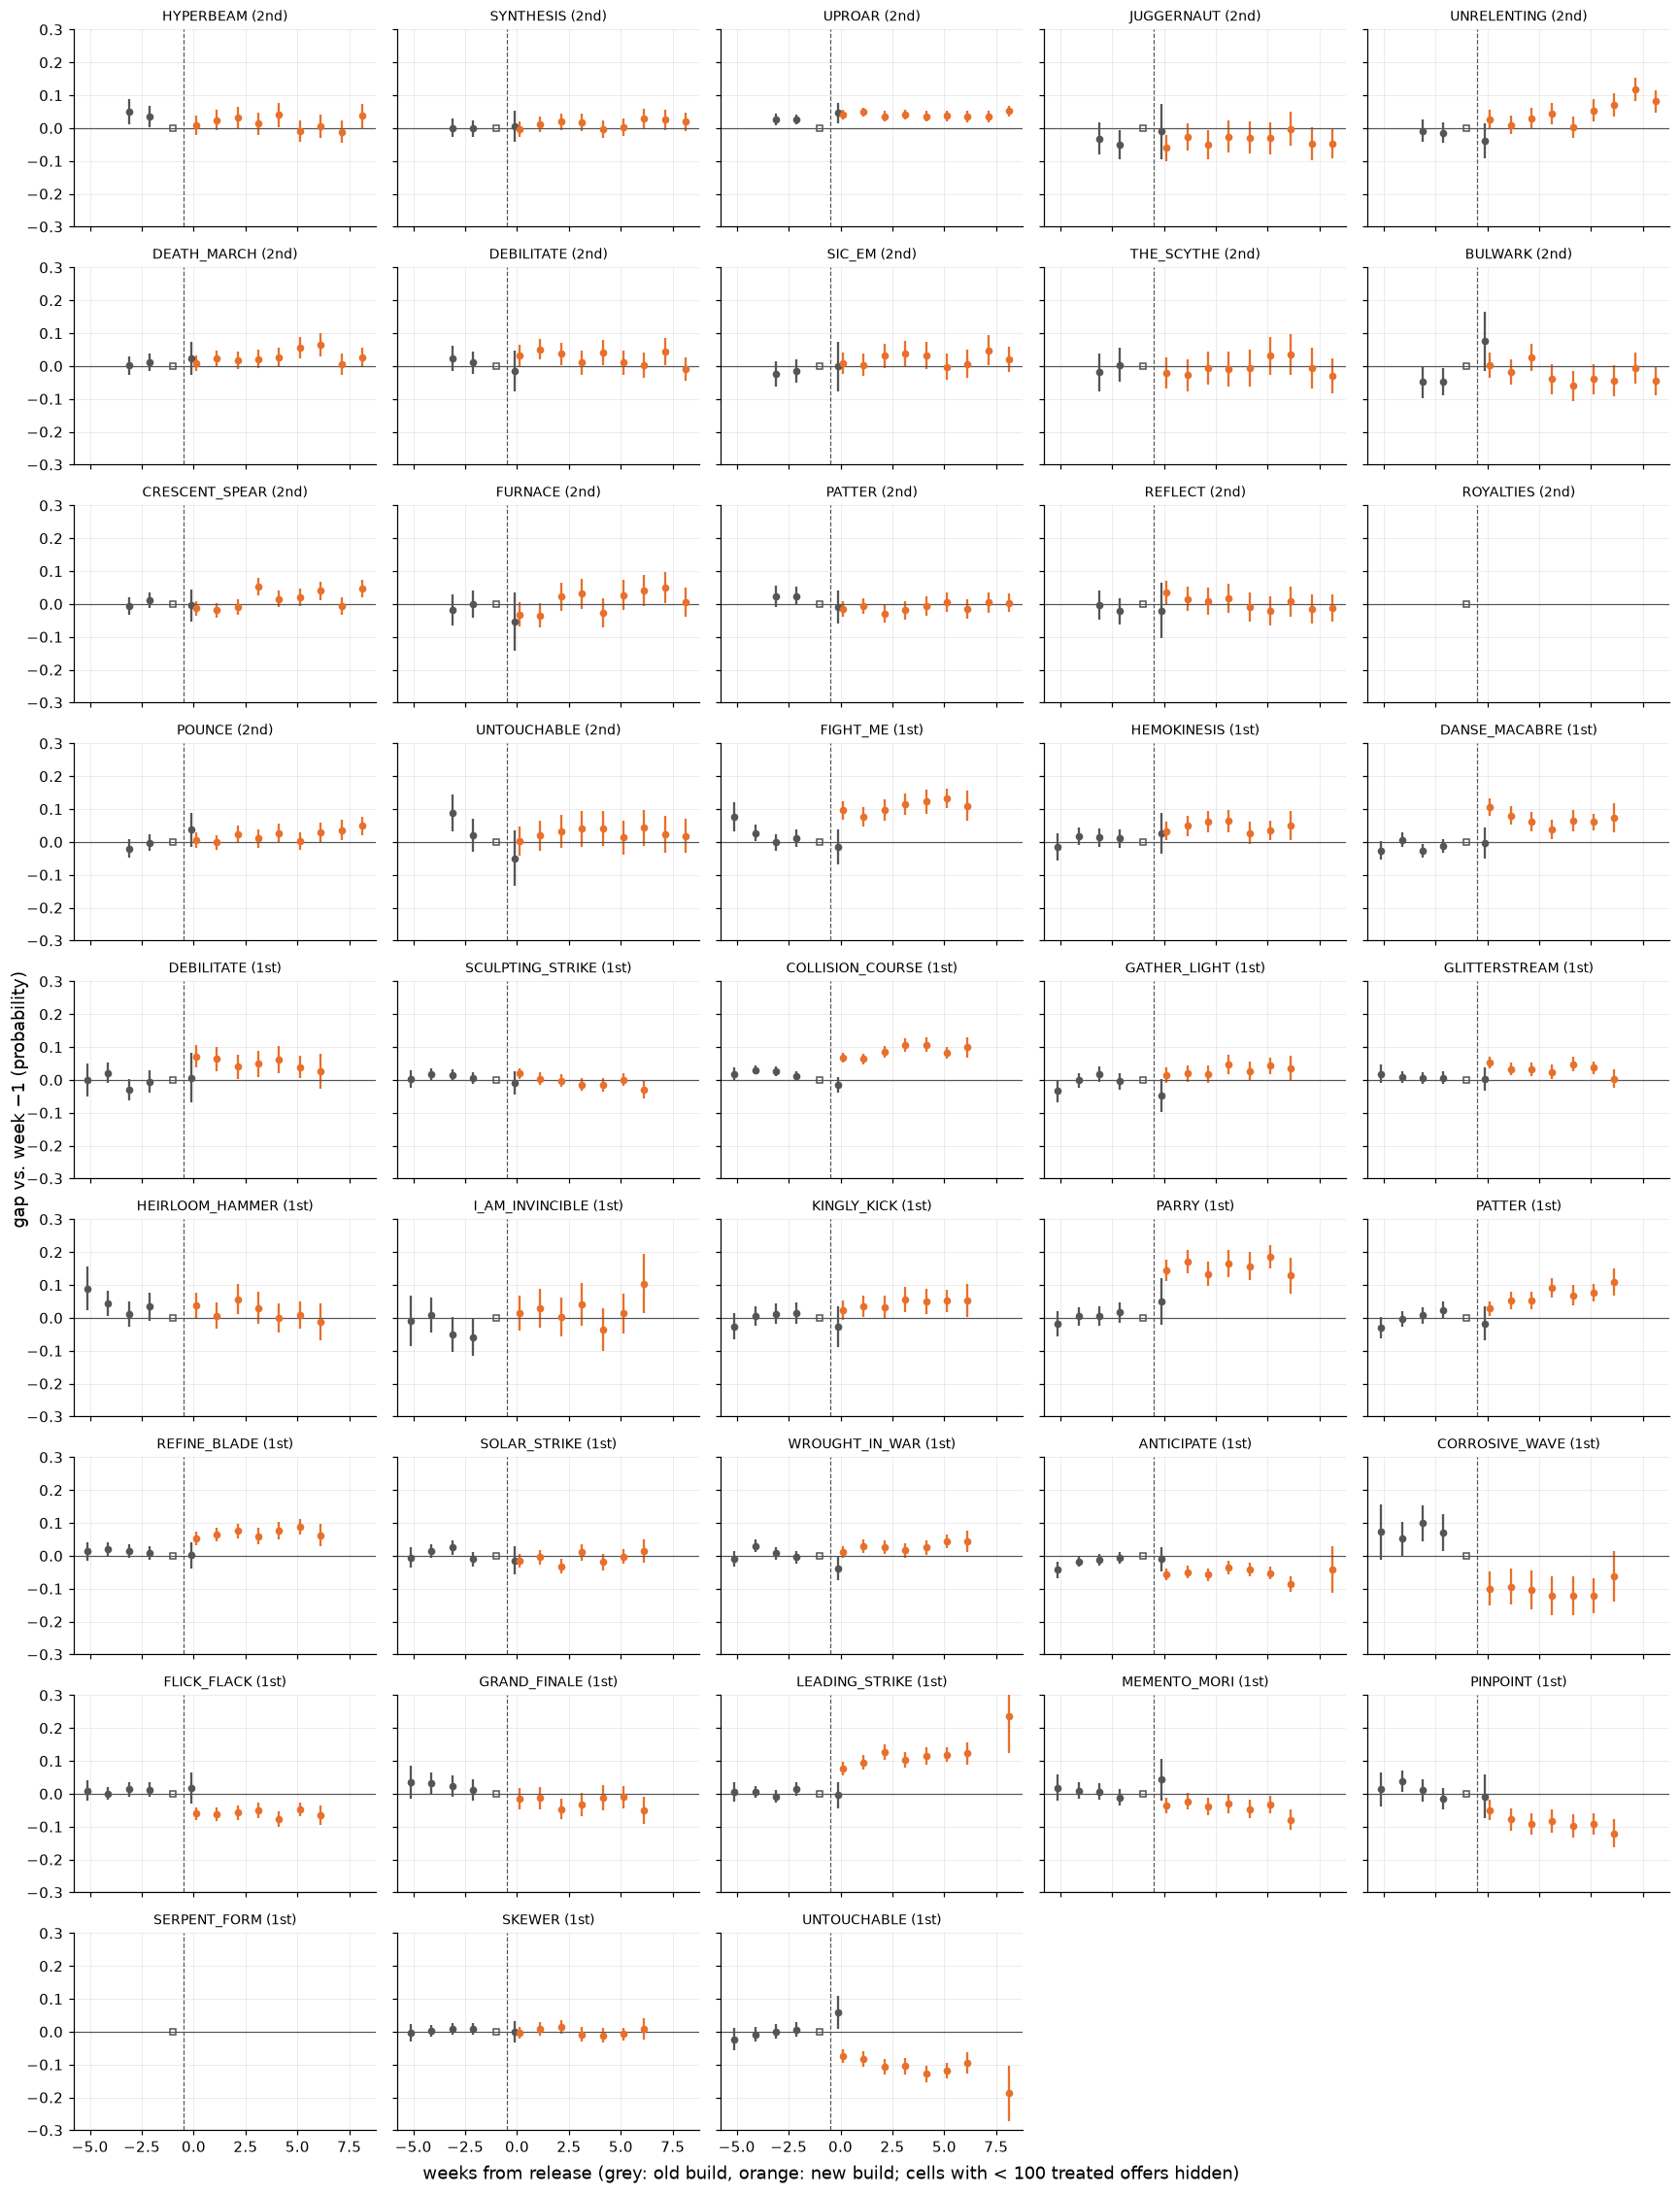

In [52]:
# Small multiples: every tweak's week-by-week gap. Thin cells (few treated offers) are
# dropped; one y-range for all panels so sizes compare directly.
MIN_OFFERS = 100          # hide cells with fewer treated offers than this
YLIM = (-0.3, 0.3)

ok = [c for c in by_window(EST).index if c in set(ES.card_patch_id[ES.error == ""])]
ncol = 5
nrow = int(np.ceil(len(ok) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.3 * nrow), sharex=True, sharey=True)
for ax, cpid in zip(axes.flat, ok):
    e = ES[(ES.card_patch_id == cpid) & (ES.n_offers >= MIN_OFFERS)]
    patch = "1st" if TW.loc[cpid, "before_builds"] == "v0.99.1" else "2nd"
    plot_event_study(e, f"{TW.loc[cpid, 'card_id']} ({patch})", ax=ax)
    ax.set(xlabel="", ylabel="", ylim=YLIM)
    ax.title.set_fontsize(9)
for ax in axes.flat[len(ok):]:
    ax.set_visible(False)
fig.supxlabel(f"weeks from release (grey: old build, orange: new build; cells with "
              f"< {MIN_OFFERS} treated offers hidden)")
fig.supylabel("gap vs. week −1 (probability)")
fig.tight_layout()
plt.show()

## 6. All tweaks: the main estimates

`did.run_all` fits every solo-estimable tweak with the main specification. Upgrade-only tweaks
(Serpent Form, Royalties, Untouchable v0.107.1) are fit on upgraded offers. Their un-upgraded
offers are fit as a placebo (`placebo_*` columns). `beta_lo` / `se_lo` are the log-odds versions,
used in section 8.

In [53]:
NUMERIC = ["beta", "se", "se_hc", "se_iid", "max_week_after", "after_week_max", "n_offers", "n_singletons_dropped", "n_runs",
           "n_treated_offers", "treated_rate_before", "treated_rate_after",
           "control_rate_before", "control_rate_after", "beta_lo", "se_lo",
           "placebo_beta", "placebo_se", "placebo_n_offers", "placebo_treated_rate_before",
           "log_ratio", "upgraded_log_ratio", "direction"]

def tidy(res):
    '''run_all output -> a flat table that saves to parquet (ci95 split, numbers as numbers).'''
    res = res.copy()
    ci = res.pop("ci95") if "ci95" in res else pd.Series([None] * len(res))
    res["ci_lo"] = [c[0] if isinstance(c, (tuple, list, np.ndarray)) else np.nan for c in ci]
    res["ci_hi"] = [c[1] if isinstance(c, (tuple, list, np.ndarray)) else np.nan for c in ci]
    for c in NUMERIC:
        if c in res:
            res[c] = pd.to_numeric(res[c], errors="coerce")
    for c in res.columns:
        if res[c].dtype == object:
            res[c] = res[c].fillna("").astype(str)
    return res.set_index("card_patch_id")

def fit_all(name, require=("se_hc",), **kw):
    '''run_all with fit_did options, saved to data/analysis/did_<name>.parquet. A saved file
    missing a `require`d column (made before PR #11) is refitted.'''
    path = OUT / f"did_{name}.parquet"
    if path.exists() and not FORCE:
        saved = pd.read_parquet(path)
        missing = [c for c in require if c not in saved]
        if not missing:
            return saved
        print(f"{name}: saved file has no {missing} (made before PR #11), refitting")
    _cache.clear()                    # run_all loads its own windows
    t0 = time.time()
    res = tidy(did.run_all(con, ref=REF, **kw))
    res.to_parquet(path)
    print(f"{name}: {len(res)} tweaks, {int((res.error != '').sum())} errors, "
          f"{time.time() - t0:.0f} s")
    return res

main = fit_all("main")
main["window"] = TW.window.reindex(main.index)
print("errors:", main.loc[main.error != "", "error"].to_dict())
display(main[["card_id", "window", "fit_on", "beta", "se", "ci_lo", "ci_hi", "se_hc", "se_iid",
              "after_week_max",
              "n_treated_offers", "treated_rate_before", "treated_rate_after",
              "control_rate_before", "control_rate_after"]]
        .sort_values("beta").style.format(precision=4))

errors: {}


,card_id,window,fit_on,beta,se,ci_lo,ci_hi,se_hc,se_iid,after_week_max,n_treated_offers,treated_rate_before,treated_rate_after,control_rate_before,control_rate_after
card_patch_id,,,,,,,,,,,,,,,
CORROSIVE_WAVE@v0.103.2/patch,CORROSIVE_WAVE,first patch (v0.103.2),all offers,-0.1655,0.0118,-0.1886,-0.1423,0.0115,0.0102,17,6913,0.4280,0.2887,0.2529,0.2751
UNTOUCHABLE@v0.103.2/patch,UNTOUCHABLE,first patch (v0.103.2),all offers,-0.0990,0.0049,-0.1085,-0.0895,0.0045,0.0043,17,39814,0.3076,0.2302,0.2529,0.2751
PINPOINT@v0.103.2/patch,PINPOINT,first patch (v0.103.2),all offers,-0.0922,0.0069,-0.1057,-0.0786,0.0068,0.0070,17,14729,0.2532,0.1835,0.2529,0.2751
FLICK_FLACK@v0.103.2/patch,FLICK_FLACK,first patch (v0.103.2),all offers,-0.0663,0.0044,-0.0750,-0.0576,0.0042,0.0043,17,39916,0.2411,0.1993,0.2529,0.2751
MEMENTO_MORI@v0.103.2/patch,MEMENTO_MORI,first patch (v0.103.2),all offers,-0.0408,0.0056,-0.0517,-0.0299,0.0054,0.0069,17,15063,0.1317,0.1129,0.2529,0.2751
ANTICIPATE@v0.103.2/patch,ANTICIPATE,first patch (v0.103.2),all offers,-0.0405,0.0038,-0.0479,-0.0330,0.0037,0.0043,17,40037,0.1658,0.1468,0.2529,0.2751
GRAND_FINALE@v0.103.2/patch,GRAND_FINALE,first patch (v0.103.2),all offers,-0.0403,0.0072,-0.0544,-0.0262,0.0070,0.0102,17,6929,0.0995,0.0829,0.2529,0.2751
PATTER@v0.107.1/patch,PATTER,second patch (v0.107.1),all offers,-0.0252,0.0066,-0.0382,-0.0122,0.0062,0.0061,9,28144,0.2598,0.2333,0.2553,0.2543
SOLAR_STRIKE@v0.103.2/patch,SOLAR_STRIKE,first patch (v0.103.2),all offers,-0.0173,0.0046,-0.0264,-0.0082,0.0045,0.0047,15,33986,0.2214,0.2039,0.2751,0.2739


In [54]:
# How much does clustering by run widen the error bars, across all tweaks?
# clustered / robust = the within-run correlation alone; clustered / iid also carries the
# unequal noise between cards (section 4).
for label, den in [("robust (se_hc)", main.se_hc), ("iid", main.se_iid)]:
    r = (main.se / den).dropna()
    print(f"clustered / {label:15s} median {r.median():.2f}, range {r.min():.2f} .. {r.max():.2f}")
p = (main.treated_rate_before + main.treated_rate_after) / 2
print("corr(clustered/iid, sqrt(p(1-p))):",
      round(float(np.corrcoef(main.se / main.se_iid, np.sqrt(p * (1 - p)))[0, 1]), 2))

clustered / robust (se_hc)  median 1.03, range 1.00 .. 1.19
clustered / iid             median 0.99, range 0.60 .. 1.25
corr(clustered/iid, sqrt(p(1-p))): 0.95


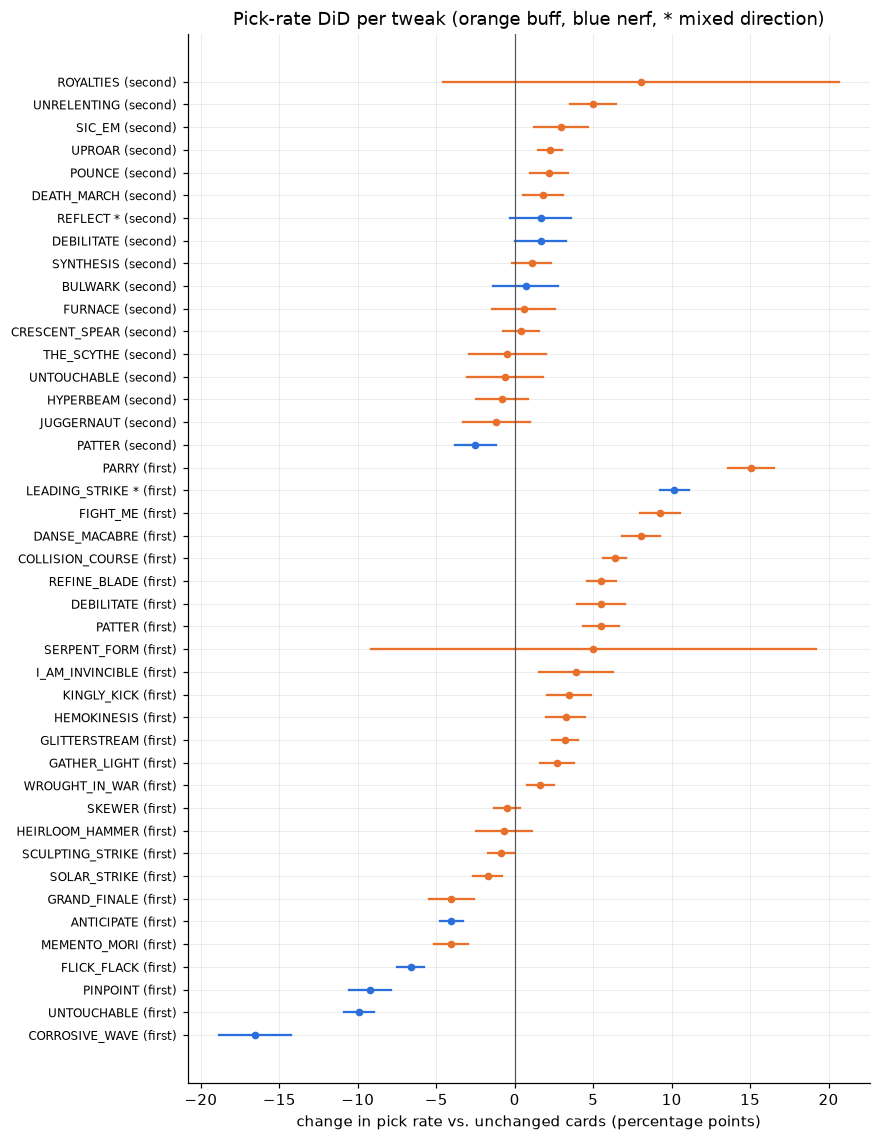

In [55]:
# Forest plot: every tweak's effect in percentage points, 95% CI. Orange = buff, blue = nerf
# (by the sign of direction x log_ratio; upgrade-only use the upgrade change's sign).
m = main[main.error == ""].copy()
dose = np.where(m.upgrade_only == "yes", m.upgrade_new.str.replace("+", "", regex=False)
                .apply(pd.to_numeric, errors="coerce")
                - m.upgrade_old.str.replace("+", "", regex=False).apply(pd.to_numeric, errors="coerce"),
                m.log_ratio)
m["buff"] = (m.direction * dose) > 0
m = m.sort_values(["window", "beta"])
y = np.arange(len(m))
fig, ax = plt.subplots(figsize=(8, 0.26 * len(m) + 1.2))
colors = np.where(m.buff, TREATED_C, CONTROL_C)
for i, (b, lo, hi, col) in enumerate(zip(m.beta, m.ci_lo, m.ci_hi, colors)):
    ax.plot([100 * lo, 100 * hi], [i, i], color=col, lw=1.5)
    ax.plot(100 * b, i, "o", color=col)
ax.axvline(0, color=GREY, lw=0.8)
ax.set_yticks(y, [f"{c}{' *' if mx == 'yes' else ''} ({w.split()[0]})"
                  for c, mx, w in zip(m.card_id, m.mixed_direction, m.window)], fontsize=8)
ax.set(xlabel="change in pick rate vs. unchanged cards (percentage points)",
       title="Pick-rate DiD per tweak (orange buff, blue nerf, * mixed direction)")
plt.show()

## 6b. Fixed horizon: after-build weeks 0–3

Several effects kept growing for weeks (Leading Strike, Pinpoint, Collision Course). The first
patch has 15–17 weeks of after-build data and the second 9 (1,393-page tables), so the main
β's aren't on the same horizon: a patch with a longer after period looks stronger just from that.
`max_week_after=3` keeps only after-build offers from weeks 0–3, which puts every tweak on
the same footing: "the effect over the first four weeks". The before block is unchanged. This
table feeds the dose-response in section 8.

In [56]:
HORIZON = 3
h3 = fit_all(f"h{HORIZON}", max_week_after=HORIZON)
h3["window"] = TW.window.reindex(h3.index)
cmp = main[["card_id", "window", "beta", "se", "after_week_max"]].join(
    h3[["beta", "se", "after_week_max"]], rsuffix="_h")
display(cmp.sort_values(["window", "beta"]).style.format(precision=4))
for w, g in cmp.groupby("window"):
    print(f"{w}: median |beta| all weeks {100 * g.beta.abs().median():.1f} pts, "
          f"weeks 0-{HORIZON} {100 * g.beta_h.abs().median():.1f} pts; clearly nonzero "
          f"{int((g.beta.abs() > 2 * g.se).sum())} -> {int((g.beta_h.abs() > 2 * g.se_h).sum())}"
          f" of {len(g)}")

,card_id,window,beta,se,after_week_max,beta_h,se_h,after_week_max_h
card_patch_id,,,,,,,,
CORROSIVE_WAVE@v0.103.2/patch,CORROSIVE_WAVE,first patch (v0.103.2),-0.1655,0.0118,17,-0.1623,0.0132,3
UNTOUCHABLE@v0.103.2/patch,UNTOUCHABLE,first patch (v0.103.2),-0.0990,0.0049,17,-0.0880,0.0054,3
PINPOINT@v0.103.2/patch,PINPOINT,first patch (v0.103.2),-0.0922,0.0069,17,-0.0832,0.0077,3
FLICK_FLACK@v0.103.2/patch,FLICK_FLACK,first patch (v0.103.2),-0.0663,0.0044,17,-0.0654,0.0049,3
MEMENTO_MORI@v0.103.2/patch,MEMENTO_MORI,first patch (v0.103.2),-0.0408,0.0056,17,-0.0361,0.0062,3
ANTICIPATE@v0.103.2/patch,ANTICIPATE,first patch (v0.103.2),-0.0405,0.0038,17,-0.0389,0.0042,3
GRAND_FINALE@v0.103.2/patch,GRAND_FINALE,first patch (v0.103.2),-0.0403,0.0072,17,-0.0428,0.0078,3
SOLAR_STRIKE@v0.103.2/patch,SOLAR_STRIKE,first patch (v0.103.2),-0.0173,0.0046,15,-0.0192,0.0051,3
SCULPTING_STRIKE@v0.103.2/patch,SCULPTING_STRIKE,first patch (v0.103.2),-0.0088,0.0041,17,-0.0040,0.0045,3


first patch (v0.103.2): median |beta| all weeks 4.5 pts, weeks 0-3 4.5 pts; clearly nonzero 23 -> 22 of 26
second patch (v0.107.1): median |beta| all weeks 1.6 pts, weeks 0-3 1.6 pts; clearly nonzero 6 -> 6 of 17


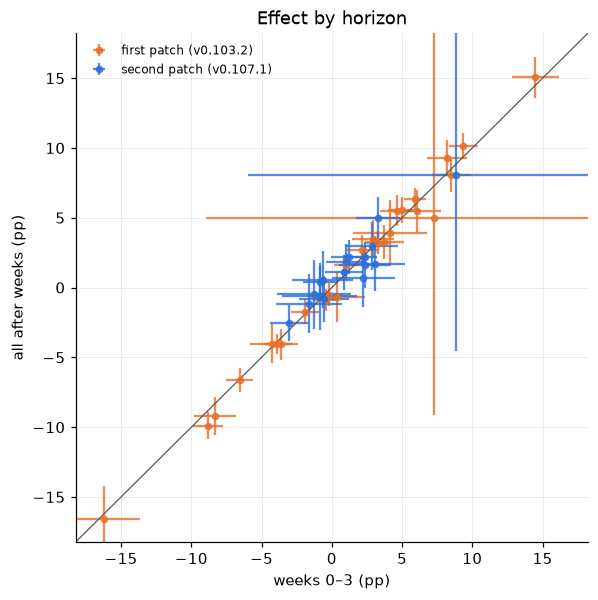

In [57]:
# All weeks vs. the first four weeks, per tweak. Points further from zero on the y-axis than
# on the x-axis grew after week 3.
fig, ax = plt.subplots(figsize=(6, 6))
for w, col in [("first patch (v0.103.2)", TREATED_C), ("second patch (v0.107.1)", CONTROL_C)]:
    g = cmp[cmp.window == w]
    ax.errorbar(100 * g.beta_h, 100 * g.beta, xerr=196 * g.se_h, yerr=196 * g.se, fmt="o",
                color=col, ecolor=col, alpha=0.8, capsize=0, ms=4, label=w)
lim = 100 * np.nanmax(np.abs(np.r_[cmp.beta, cmp.beta_h])) * 1.1
ax.plot([-lim, lim], [-lim, lim], color=GREY, lw=0.8)
ax.set(xlabel=f"weeks 0–{HORIZON} (pp)", ylabel="all after weeks (pp)", xlim=(-lim, lim),
       ylim=(-lim, lim), title="Effect by horizon")
ax.legend(frameon=False, fontsize=8)
plt.show()

## 7. Robustness

Each check refits all tweaks with one option changed. They're saved like the main fit, so the
first run takes a while and later runs load from disk.

What counts as "robust": the checks shouldn't change the story. Most estimates should stay within
their error bars of the main estimate, and no sign flips should happen among the clearly nonzero
ones. A check that moves many cards the same way is a finding about the design.

In [ ]:
TOP_N_UPLOADERS_ALL = 10
top_all = con.execute(f'''
    SELECT uploader_hash, count(DISTINCT run_key) AS runs FROM runs
    WHERE n_players = 1 AND uploader_hash IS NOT NULL
    GROUP BY 1 ORDER BY 2 DESC LIMIT {TOP_N_UPLOADERS_ALL}''').df()
display(top_all)

CHECKS = {
    "pooled_groups": dict(pooled_groups=True),
    "tagged": dict(group="tagged"),
    "untagged": dict(group="untagged"),
    "drop_shared_screens": dict(drop_shared_screens=True),
    "drop_behavior_flags": dict(drop_behavior_flags=True),
}
if len(top_all):
    CHECKS["drop_top_uploaders"] = dict(drop_uploaders=top_all.uploader_hash.tolist())
else:
    print("No uploader_hash in these tables (pages downloaded before player_token): "
          "heavy-uploader check skipped.")
checks = {name: fit_all(name, require=(), **kw) for name, kw in CHECKS.items()}

In [59]:
def compare(check):
    j = main[["card_id", "beta", "se"]].join(check[["beta", "se", "error"]], rsuffix="_chk")
    j = j[j.error == ""].dropna(subset=["beta", "beta_chk"])
    j["shift_in_se"] = (j.beta_chk - j.beta) / j.se
    j["sign_flip"] = (np.sign(j.beta) != np.sign(j.beta_chk)) & (j.beta.abs() > 2 * j.se)
    return j

summary = pd.DataFrame({name: {
    "n": len(j := compare(c)),
    "median |shift| (in main se)": j.shift_in_se.abs().median(),
    "share beyond 2 se": (j.shift_in_se.abs() > 2).mean(),
    "sign flips (|beta| > 2 se)": int(j.sign_flip.sum()),
    "slope of check on main": np.polyfit(j.beta, j.beta_chk, 1)[0] if len(j) > 2 else np.nan,
} for name, c in checks.items()}).T
display(summary.style.format(precision=3))

,n,median |shift| (in main se),share beyond 2 se,sign flips (|beta| > 2 se),slope of check on main
pooled_groups,43.000,0.076,0.000,0.000,1.005
tagged,43.000,2.265,0.581,0.000,1.039
untagged,43.000,0.344,0.000,0.000,0.982
drop_shared_screens,43.000,0.047,0.000,0.000,0.992
drop_behavior_flags,43.000,0.015,0.000,0.000,1.002
drop_top_uploaders,43.000,0.060,0.000,0.000,1.000


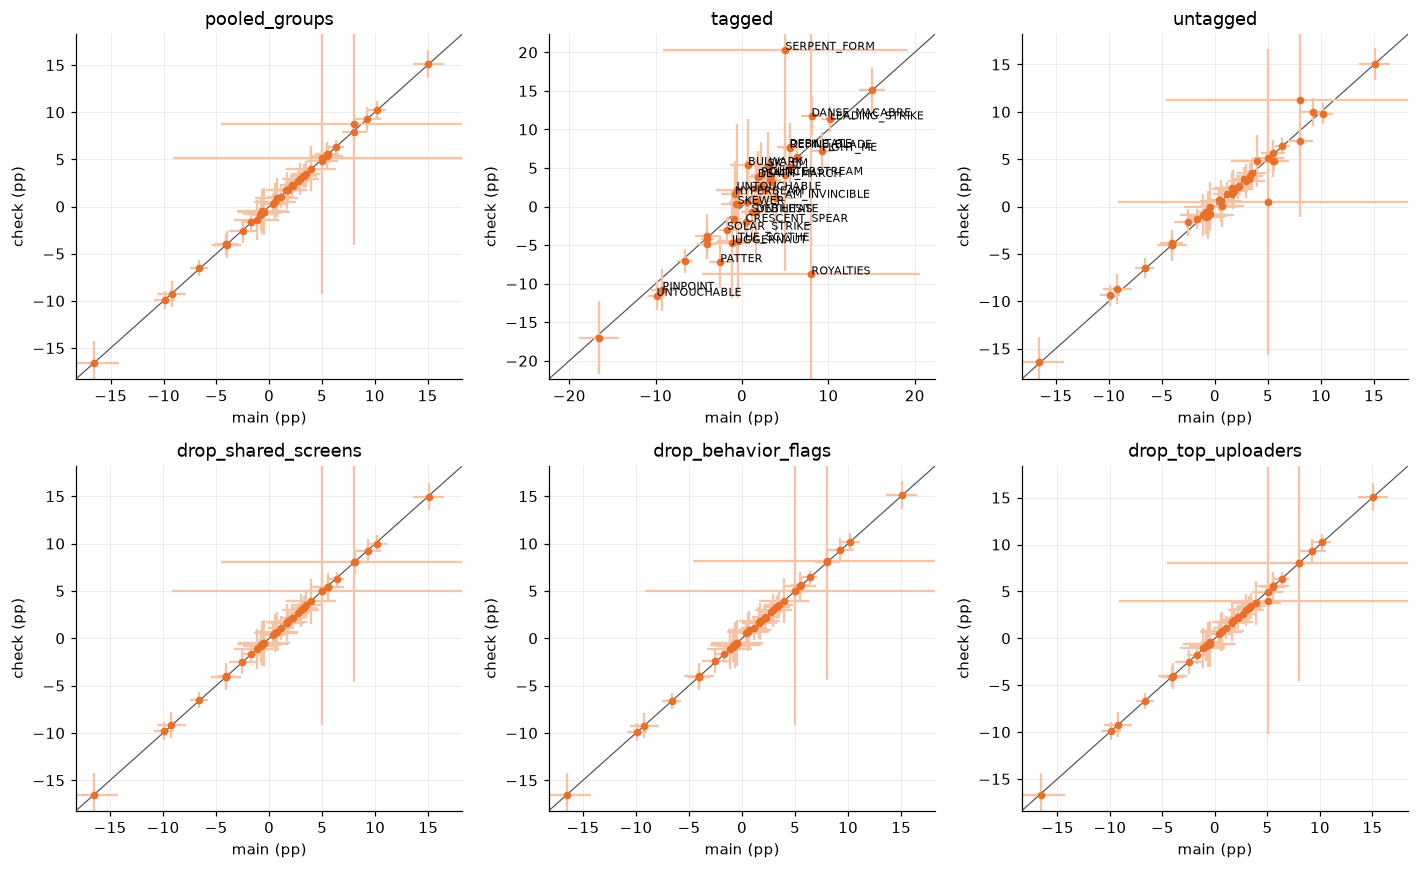

In [60]:
# Each check against the main estimate. Points on the diagonal = the check changes nothing.
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax in axes.flat[len(checks):]:
    ax.set_visible(False)
for ax, (name, c) in zip(axes.flat, checks.items()):
    j = compare(c)
    lim = 100 * np.nanmax(np.abs(np.r_[j.beta, j.beta_chk])) * 1.1
    ax.plot([-lim, lim], [-lim, lim], color=GREY, lw=0.8)
    ax.errorbar(100 * j.beta, 100 * j.beta_chk, xerr=196 * j.se, yerr=196 * j.se_chk,
                fmt="o", color=TREATED_C, ecolor="#f3c5a6", capsize=0, ms=4)
    for _, r in j[j.shift_in_se.abs() > 2].iterrows():
        ax.annotate(r.card_id, (100 * r.beta, 100 * r.beta_chk), fontsize=7)
    ax.set(title=name, xlabel="main (pp)", ylabel="check (pp)", xlim=(-lim, lim), ylim=(-lim, lim))
fig.tight_layout()
plt.show()

### The second patch's before block

The second patch compares v0.103.3 (a short stable hotfix) with v0.107.1. v0.103.2 carries the
same card versions as v0.103.3 but is three times the size. It's left out because it's the *after*
block of the first patch: the cards changed there were still settling during it, and many of them
are controls here. Two checks:

- **pooled before**: v0.103.2 + v0.103.3 as the before block. More data, but the controls
  include that settling drift.
- **no first-patch controls**: v0.103.3 alone, with every card changed in the first patch dropped
  from the controls. This removes the drift directly.

If all three agree, the choice doesn't matter. If "pooled before" differs from the other two,
the drift is real and the main design was the right call.

In [61]:
W = pd.read_csv(REF / "windows.csv", dtype=str, keep_default_na=False)
FIRST_PATCH_CARDS = set(W[(W.level == "card_patch") & (W.after_builds == "v0.103.2")].card_id)
print(f"cards changed in the first patch (any kind): {len(FIRST_PATCH_CARDS)}")

def second_patch_checks():
    rows = []
    second = by_window(EST[EST.before_builds == "v0.103.3"])
    for color, g in second.groupby("color", sort=False):
        _cache.clear()
        t0 = time.time()
        pooled = did.load_block_data(con, color, "v0.103.2 v0.103.3", "v0.107.1", ref=REF)
        alone = did.load_block_data(con, color, "v0.103.3", "v0.107.1", ref=REF)
        print(f"  {color}: loaded ({time.time() - t0:.0f} s)")
        for cpid, t in g.iterrows():
            kw = dict(upgraded=True) if t.upgrade_only == "yes" else {}
            no_first = alone[~alone.card_id.isin(FIRST_PATCH_CARDS - {t.card_id})]
            for name, data in [("main", alone), ("pooled before", pooled),
                               ("no first-patch controls", no_first)]:
                try:
                    r = did.fit_did(data, cpid, ref=REF, **kw)
                    rows.append({"card_patch_id": cpid, "card": t.card_id, "variant": name,
                                 "beta": r["beta"], "se": r["se"],
                                 "n_treated_offers": r["n_treated_offers"],
                                 "n_controls": len(did.control_cards(cpid, df=data, ref=REF))})
                except Exception as e:
                    rows.append({"card_patch_id": cpid, "card": t.card_id, "variant": name,
                                 "error": f"{type(e).__name__}: {e}"})
        del pooled, alone
    return pd.DataFrame(rows)

path = OUT / "did_second_patch_checks.parquet"
if path.exists() and not FORCE:
    SP = pd.read_parquet(path)
else:
    SP = second_patch_checks()
    SP.to_parquet(path)
sp = SP.pivot_table(index="card", columns="variant", values=["beta", "se"])
display(sp.style.format(precision=4))

cards changed in the first patch (any kind): 87


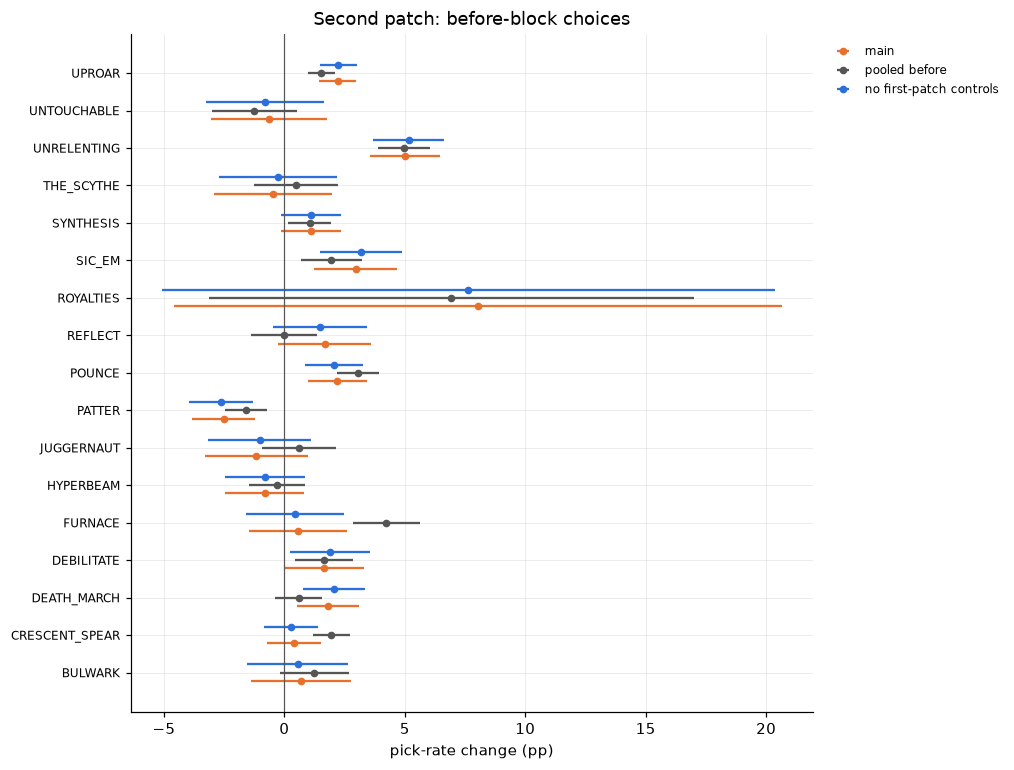

In [62]:
# The three versions of each second-patch tweak side by side (percentage points, 95% CI).
order = ["main", "pooled before", "no first-patch controls"]
cards = sorted(SP.card.unique())
fig, ax = plt.subplots(figsize=(8, 0.4 * len(cards) + 1.2))
for k, (name, col) in enumerate(zip(order, [TREATED_C, GREY, CONTROL_C])):
    s = SP[SP.variant == name].set_index("card").reindex(cards)
    y = np.arange(len(cards)) + (k - 1) * 0.22
    ax.errorbar(100 * s.beta, y, xerr=196 * s.se, fmt="o", color=col, ecolor=col,
                capsize=0, label=name, ms=4)
ax.axvline(0, color=GREY, lw=0.8)
ax.set_yticks(np.arange(len(cards)), cards, fontsize=8)
ax.set(xlabel="pick-rate change (pp)", title="Second patch: before-block choices")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

## 8. Step 3: dose-response

One point per tweak.

- **x**: direction × ln(new/old) of the main field. Positive = buff.
- **y**: β on the log-odds scale (`beta_lo`). On this scale a card picked 5% of the time and one
  picked 50% of the time can move comparably. The conversion is a first-order approximation,
  `beta / (p(1−p))`, with p = the card's pick rate before.

Kept off the fitted line and drawn separately:

- **Mixed-direction tweaks** (Leading Strike, Reflect): one number went up and another down, so
  there's no single x.
- **Upgrade-only tweaks**: their x is the upgraded card's change, a different kind of dose.

**Which estimates:** the fixed-horizon ones from section 6b (`DR = h3`), so both patches are
measured over the same four weeks. Set `DR = main` to see the all-weeks version.

**The fit** is a weighted meta-regression. Each point is an estimate with its own error bar,
and cards also genuinely differ (+1 damage is worth more on some cards than others). So the
weights are 1 / (se² + τ²), where τ² is the between-card scatter estimated from the data
(method of moments, as in a random-effects meta-analysis). With τ² = 0 this is plain
inverse-variance weighting, and the few most precise cards dominate the line. With τ² > 0 every
card counts more evenly.

Four models:

- **one slope**: y = a + b·x
- **+ patch shift**: y = a + b·x + c·[second patch]. Is the second patch weaker at the same
  change size?
- **slope per patch**: y = a + c·[second] + b₁·x·[first] + b₂·x·[second]
- **buff/nerf + patch**: y = a + c·[second] + b₊·x⁺ + b₋·x⁻, where x⁺ = max(x, 0) and
  x⁻ = min(x, 0). This is the fair buff-vs-nerf test. Without the patch term, the weaker
  second patch (3 of the 8 nerfs) could fake a flatter nerf slope.

The intercept `a` is the effect of a zero-size change. A nonzero `a` would mean being in the
patch notes moves picks by itself.

In [63]:
def meta_regression(y, se, X):
    '''Random-effects meta-regression. Returns (coef, coef_se, tau2, Q, df).
    tau2 by method of moments (DerSimonian-Laird generalized to regression):
      Q = sum w (y - X b_fe)^2 with w = 1/se^2,
      tau2 = max(0, (Q - (k - p)) / (sum w - tr((X'WX)^-1 X'W^2 X))).
    Then weighted least squares with w* = 1/(se^2 + tau2).'''
    y, se, X = np.asarray(y, float), np.asarray(se, float), np.asarray(X, float)
    k, p = X.shape
    w = 1 / se ** 2
    XtW = X.T * w
    b_fe = np.linalg.solve(XtW @ X, XtW @ y)
    Q = float((w * (y - X @ b_fe) ** 2).sum())
    denom = w.sum() - np.trace(np.linalg.solve(XtW @ X, (X.T * w ** 2) @ X))
    tau2 = max(0.0, (Q - (k - p)) / denom)
    ws = 1 / (se ** 2 + tau2)
    XtWs = X.T * ws
    cov = np.linalg.inv(XtWs @ X)
    b = cov @ (XtWs @ y)
    return b, np.sqrt(np.diag(cov)), tau2, Q, k - p

DR = h3                   # or main, for all after weeks
m = DR[DR.error == ""].copy()
m["x"] = m.direction * m.log_ratio
m["x_upg"] = m.direction * m.upgraded_log_ratio
line = m[(m.mixed_direction != "yes") & (m.upgrade_only != "yes")
         & m.x.notna() & m.beta_lo.notna() & (m.se_lo > 0)]
print(f"{len(line)} tweaks on the line; left off: "
      f"{sorted(set(m.card_id) - set(line.card_id))}")

second = (line.before_builds == "v0.103.3").astype(float).to_numpy()
x = line.x.to_numpy()
one = np.ones(len(line))
designs = {
    "one slope": (np.column_stack([one, x]), ["intercept a", "slope b"]),
    "+ patch shift": (np.column_stack([one, x, second]),
                      ["intercept a", "slope b", "second-patch shift c"]),
    "slope per patch": (np.column_stack([one, second, x * (1 - second), x * second]),
                        ["intercept a", "second-patch shift c", "slope, first patch",
                         "slope, second patch"]),
    "buff/nerf + patch": (np.column_stack([one, second, np.clip(x, 0, None),
                                           np.clip(x, None, 0)]),
                          ["intercept a", "second-patch shift c", "buff slope b+",
                           "nerf slope b-"]),
}
fits = {k: meta_regression(line.beta_lo, line.se_lo, X) for k, (X, _) in designs.items()}
names = {k: n for k, (_, n) in designs.items()}
rows = []
for model, (b, s, tau2, Q, dof) in fits.items():
    for n, bi, si in zip(names[model], b, s):
        rows.append({"model": model, "term": n, "coef": bi, "se": si, "z": bi / si,
                     "tau2": tau2, "Q": Q, "df": dof})
display(pd.DataFrame(rows).set_index(["model", "term"]).style.format(precision=4))
print(f"on the line: {int((second == 0).sum())} first-patch and {int(second.sum())} "
      f"second-patch tweaks; {int((x < 0).sum())} nerfs")

38 tweaks on the line; left off: ['LEADING_STRIKE', 'REFLECT', 'ROYALTIES', 'SERPENT_FORM']


on the line: 24 first-patch and 14 second-patch tweaks; 8 nerfs


**Reading the slopes.** The slope is the change in log-odds of picking per unit of ln(new/old).
For a feel: +1 damage on a 7-damage card is ln(8/7) ≈ 0.13. Multiply by the slope for the
log-odds change. For a card picked 30% of the time, multiply that by 0.3 × 0.7 = 0.21 for
percentage points.

**Q vs. df.** If Q is much bigger than df, the cards scatter around the line more than their
error bars allow, which is expected. τ² measures how much. Report it: "tweaks of the same size
had different effects on different cards, with an sd of √τ² in log-odds."

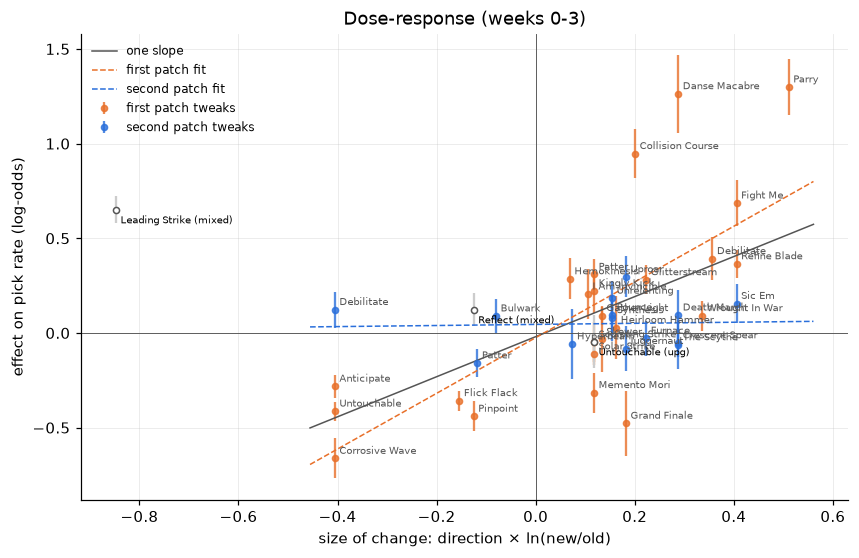

In [64]:
# Dose-response plot: log-odds effect vs. signed log change. Filled = on the line;
# open = mixed-direction (at their main field's x) or upgrade-only (at the upgraded x).
fig, ax = plt.subplots(figsize=(9, 5.5))
for sec, col, lab in [(0, TREATED_C, "first patch"), (1, CONTROL_C, "second patch")]:
    g = line[second == sec]
    ax.errorbar(g.x, g.beta_lo, yerr=1.96 * g.se_lo, fmt="o", color=col, ecolor=col,
                alpha=0.8, capsize=0, label=f"{lab} tweaks")
for _, r in line.iterrows():
    ax.annotate(r.card_id.replace("_", " ").title(), (r.x, r.beta_lo), fontsize=6.5,
                xytext=(3, 3), textcoords="offset points", color=GREY)
off = m[(m.mixed_direction == "yes") | (m.upgrade_only == "yes")]
for _, r in off.iterrows():
    x = r.x_upg if r.upgrade_only == "yes" else r.x
    if pd.notna(x) and pd.notna(r.beta_lo):
        ax.errorbar(x, r.beta_lo, yerr=1.96 * r.se_lo, fmt="o", mfc="white", color=GREY,
                    ecolor="#ccc", capsize=0)
        ax.annotate(r.card_id.replace("_", " ").title()
                    + (" (upg)" if r.upgrade_only == "yes" else " (mixed)"),
                    (x, r.beta_lo), fontsize=6.5, xytext=(3, -9), textcoords="offset points")
xs = np.linspace(min(line.x.min(), 0) - 0.05, max(line.x.max(), 0) + 0.05, 100)
b = fits["one slope"][0]
ax.plot(xs, b[0] + b[1] * xs, color=GREY, lw=1, label="one slope")
b = fits["slope per patch"][0]
ax.plot(xs, b[0] + b[2] * xs, color=TREATED_C, lw=1, ls="--", label="first patch fit")
ax.plot(xs, b[0] + b[1] + b[3] * xs, color=CONTROL_C, lw=1, ls="--", label="second patch fit")
ax.axhline(0, color=GREY, lw=0.6)
ax.axvline(0, color=GREY, lw=0.6)
ax.set(xlabel="size of change: direction × ln(new/old)",
       ylabel="effect on pick rate (log-odds)",
       title=f"Dose-response ({'weeks 0-' + str(HORIZON) if DR is h3 else 'all after weeks'})")
ax.legend(frameon=False, fontsize=8)
plt.show()

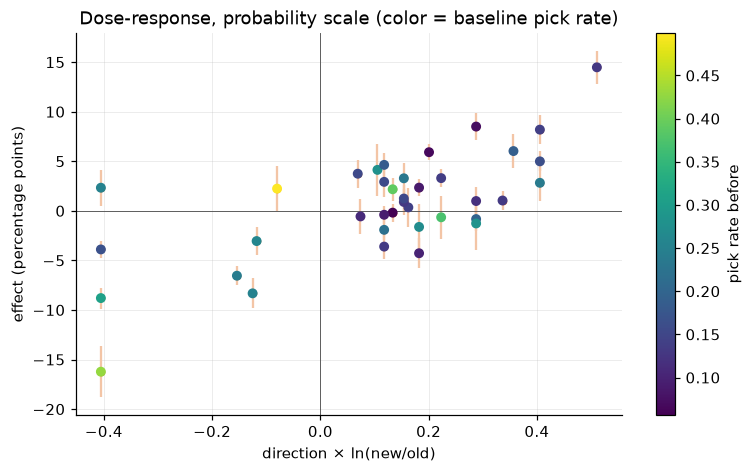

In [65]:
# The same plot on the percentage-point scale, for comparison (no fit). If the story only
# holds on one scale, say so.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(line.x, 100 * line.beta, yerr=196 * line.se, fmt="o", color=TREATED_C,
            ecolor="#f3c5a6", capsize=0)
sc = ax.scatter(line.x, 100 * line.beta, c=line.treated_rate_before, cmap="viridis", s=30, zorder=3)
plt.colorbar(sc, ax=ax, label="pick rate before")
ax.axhline(0, color=GREY, lw=0.6)
ax.axvline(0, color=GREY, lw=0.6)
ax.set(xlabel="direction × ln(new/old)", ylabel="effect (percentage points)",
       title="Dose-response, probability scale (color = baseline pick rate)")
plt.show()

### Upgrade-only tweaks: the built-in placebo

These changes only touched the upgraded card, so un-upgraded offers of it should show no effect.
An effect there means players reacted to the card being in the patch notes (attention or
misreading), not to its strength.

In [66]:
up = main[main.upgrade_only == "yes"]
display(up[["card_id", "upgrade_old", "upgrade_new", "fit_on", "beta", "se", "n_treated_offers",
            "placebo_beta", "placebo_se", "placebo_n_offers", "error", "placebo_error"]]
        .style.format(precision=4))

,card_id,upgrade_old,upgrade_new,fit_on,beta,se,n_treated_offers,placebo_beta,placebo_se,placebo_n_offers,error,placebo_error
card_patch_id,,,,,,,,,,,,
SERPENT_FORM@v0.103.2/patch,SERPENT_FORM,+1,+2,upgraded offers,0.0502,0.0722,190,0.0041,0.0118,987038.0000,,
ROYALTIES@v0.107.1/patch,ROYALTIES,+5,+10,upgraded offers,0.0803,0.0644,162,-0.0304,0.0118,1043765.0000,,
UNTOUCHABLE@v0.107.1/patch,UNTOUCHABLE,+2,+3,upgraded offers,-0.0064,0.0124,7430,-0.0131,0.0048,1603107.0000,,


## 9. What to write down

Once the numbers look sane, these go into `SPIROMETRY.md` ("Phase 5
results") and PLAN.md's status:

- Parser version and snapshot extent of the tables used; the duplicate-upload share (section 0).
- Offer-rate check: how many flagged, which, and what you decided about each.
- Clustered/robust SE ratio (median and range): the within-run correlation.
- Pre-trends: which tweaks show a slope before release, and whether their estimates are kept.
- Main estimates: how many clearly nonzero, and in the direction of the change.
- Robustness: the summary table's headline (median shift, sign flips), and the second-patch
  before-block result.
- Fixed horizon: how the two patches compare over weeks 0–3.
- Dose-response (weeks 0–3): slope, intercept, τ², the second-patch shift, and buff vs.
  nerf with the patch term in.
- Offer-rate: which flags survive against same-rarity controls.
- Section 0's copies table.
- Upgrade-only placebos.

Open decisions this notebook informs: ascension as one level each (check `n_singletons_dropped`
in the main table), how many uploaders to drop, and whether the dedup rebuild is urgent.

In [67]:
con.close()   # release runs.duckdb so a rebuild can take the write lock